In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/vijayveersingh/kepler-and-tess-exoplanet-data/PS_2025.02.03_05.09.36.csv
/kaggle/input/datasets/vijayveersingh/kepler-and-tess-exoplanet-data/STELLARHOSTS_2025.02.03_06.11.17.csv
/kaggle/input/datasets/vijayveersingh/kepler-and-tess-exoplanet-data/TOI_2025.02.03_06.18.31.csv
/kaggle/input/datasets/vijayveersingh/kepler-and-tess-exoplanet-data/keplerstellar_2025.02.03_04.41.47.csv
/kaggle/input/datasets/vijayveersingh/kepler-and-tess-exoplanet-data/q1_q17_dr25_koifpp_2025.02.03_06.14.34.csv
/kaggle/input/datasets/vijayveersingh/kepler-and-tess-exoplanet-data/q1_q17_dr25_tce_2025.02.03_04.32.18.csv
/kaggle/input/datasets/vijayveersingh/kepler-and-tess-exoplanet-data/q1_q8_koi_2025.02.03_04.12.15.csv


In [2]:
pip install lightkurve 

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 39.8 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 21.5 MB/s  0:00:00
  Created wheel for fbpca: filename=fbpca-1.0-py3-none-any.whl size=11429 sha256=9d2b20eda3fb1ce7d3098d5513705b401835f34cd4cf8b71cac5590892617c69
  Stored in directory: /root/.cache/pip/wheels/30/85/d4/289ba063a9ae0ba3189c6914e992722575868b2cb41100401b
  Created wheel for memoization: filename=memoization-0.4.0-py3-none-any.whl size=50537 sha256=de8d844cc3a3a6e838ecf8c50df52a8f70ec44b898ff7fda8ae6ac3b3e69b0a7
  Stored in directory: /root/.cache/pip/wheels/5c/ef/65/c51178502ccdadab909ffa9339a9a89701991df15f9d3b2c32
Successfully built fbpca memoization
   ━━━━━━━━━

In [3]:
import pandas as pd
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report, precision_score, recall_score

base = "/kaggle/input/datasets/vijayveersingh/kepler-and-tess-exoplanet-data/"
koi = pd.read_csv(base + "q1_q8_koi_2025.02.03_04.12.15.csv", comment="#")


In [4]:
koi.head()

,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,9388479,K00936.02,Kepler-732 c,CONFIRMED,CANDIDATE,NaN,NaN,NaN,NaN,NaN,...,-200.0,4.76,0.3,-0.3,0.496,0.023,-0.023,283.73203,45.958771,15.073
1,8359498,K00127.01,Kepler-77 b,CONFIRMED,CANDIDATE,NaN,NaN,NaN,NaN,NaN,...,-50.0,4.45,0.1,-0.1,1.039,0.045,-0.045,289.60797,44.345421,13.938
2,9406990,K00937.01,Kepler-733 b,CONFIRMED,CANDIDATE,NaN,NaN,NaN,NaN,NaN,...,-102.0,4.60,0.3,-0.3,0.780,0.240,-0.240,293.01828,45.914688,15.412
3,9415172,K00938.01,Kepler-255 c,CONFIRMED,CANDIDATE,NaN,NaN,NaN,NaN,NaN,...,-128.0,4.58,0.3,-0.3,0.800,0.380,-0.380,296.06424,45.976841,15.596
4,9415172,K00938.02,Kepler-255 d,CONFIRMED,CANDIDATE,NaN,NaN,NaN,NaN,NaN,...,-128.0,4.58,0.3,-0.3,0.800,0.380,-0.380,296.06424,45.976841,15.596


In [5]:
print("Formato:", koi.shape)
print()
print(koi["koi_disposition"].value_counts())
print()
koi[["kepid", "kepoi_name", "koi_disposition", "koi_period", "koi_depth",
     "koi_duration", "koi_prad", "koi_model_snr"]].head()

Formato: (3865, 49)

koi_disposition
CONFIRMED            2317
FALSE POSITIVE        701
NOT DISPOSITIONED     579
CANDIDATE             268
Name: count, dtype: int64



,kepid,kepoi_name,koi_disposition,koi_period,koi_depth,koi_duration,koi_prad,koi_model_snr
0,9388479,K00936.02,CONFIRMED,0.893048,738,1.1894,1.47,102.7
1,8359498,K00127.01,CONFIRMED,3.578783,11445,2.8982,10.93,2178.0
2,9406990,K00937.01,CONFIRMED,20.834950,994,4.0548,2.42,46.3
3,9415172,K00938.01,CONFIRMED,9.946049,1034,3.4912,2.90,54.7
4,9415172,K00938.02,CONFIRMED,1.045632,214,1.8348,1.28,27.5


In [6]:
df = koi[koi["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])].copy()

In [7]:
df["y"] = (df["koi_disposition"] == "CONFIRMED").astype(int)

In [8]:
feats = ["koi_period", "koi_duration", "koi_depth", "koi_impact", "koi_model_snr",
         "koi_prad", "koi_teq", "koi_steff", "koi_slogg", "koi_srad", "koi_kepmag"]

print("Linhas rotuladas:", len(df))
print("Estrelas únicas:", df["kepid"].nunique())
print()
print("Proporção das classes:")
print(df["y"].value_counts(normalize=True).round(3))
print()
print("Valores faltando (%):")
print((df[feats].isna().mean() * 100).round(1))

Linhas rotuladas: 3018
Estrelas únicas: 2350

Proporção das classes:
y
1    0.768
0    0.232
Name: proportion, dtype: float64

Valores faltando (%):
koi_period       0.0
koi_duration     0.0
koi_depth        0.0
koi_impact       0.0
koi_model_snr    0.0
koi_prad         0.0
koi_teq          0.0
koi_steff        0.0
koi_slogg        0.0
koi_srad         0.0
koi_kepmag       0.0
dtype: float64


In [9]:
X = df[feats]
y = df["y"]
grupos = df["kepid"]

modelo = RandomForestClassifier(
    n_estimators = 500,
    class_weight = "balanced",
    random_state = 42,
    n_jobs = -1,
)

In [10]:
proba = cross_val_predict(
    modelo, X, y, groups=grupos,
    cv=GroupKFold(n_splits=5), method="predict_proba"
)[:, 1]

print("ROC-AUC:", round(roc_auc_score(y, proba), 3))
print("PR-AUC :", round(average_precision_score(y, proba), 3))
print()
print(classification_report(y, proba > 0.5, target_names=["Falso positivo", "Planeta"]))

ROC-AUC: 0.915
PR-AUC : 0.967

                precision    recall  f1-score   support

Falso positivo       0.84      0.63      0.72       701
       Planeta       0.90      0.96      0.93      2317

      accuracy                           0.89      3018
     macro avg       0.87      0.80      0.82      3018
  weighted avg       0.88      0.89      0.88      3018



In [11]:
modelo.fit(X, y)
imp = pd.Series(modelo.feature_importances_, index=feats).sort_values(ascending=False)
print("Importância das features:")
print(imp.round(3))
print()

Importância das features:
koi_impact       0.176
koi_teq          0.142
koi_period       0.124
koi_model_snr    0.118
koi_prad         0.116
koi_duration     0.075
koi_depth        0.074
koi_steff        0.050
koi_kepmag       0.046
koi_srad         0.044
koi_slogg        0.035
dtype: float64



In [12]:
print("limiar | precision(FP) | recall(FP) | recall(planeta)")
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    pred = (proba > t).astype(int)
    p_fp = precision_score(y, pred, pos_label=0)
    r_fp = recall_score(y, pred, pos_label=0)
    r_pl = recall_score(y, pred, pos_label=1)
    print(f"{t:6.1f} | {p_fp:13.2f} | {r_fp:10.2f} | {r_pl:15.2f}")

limiar | precision(FP) | recall(FP) | recall(planeta)
   0.2 |          0.97 |       0.31 |            1.00
   0.3 |          0.94 |       0.43 |            0.99
   0.4 |          0.89 |       0.53 |            0.98
   0.5 |          0.84 |       0.63 |            0.96
   0.6 |          0.76 |       0.70 |            0.93
   0.7 |          0.68 |       0.79 |            0.89
   0.8 |          0.58 |       0.86 |            0.81
   0.9 |          0.44 |       0.92 |            0.64


In [13]:
from sklearn.ensemble import HistGradientBoostingClassifier

d = df.copy()


In [14]:
d["log_period"] = np.log10(d["koi_period"])
d["log_depth"]  = np.log10(d["koi_depth"].clip(lower=1))
d["log_snr"]    = np.log10(d["koi_model_snr"].clip(lower=0.1))
d["rp_rs"]      = d["koi_prad"] / (109.1 * d["koi_srad"])   # raio planeta / raio estrela

In [15]:
rho = (10 ** (d["koi_slogg"] - 4.438)) / d["koi_srad"]       # densidade relativa ao Sol
dur_esp = 13.0 * (d["koi_period"] / 365.25) ** (1/3) * rho ** (-1/3)
d["dur_ratio"] = d["koi_duration"] / dur_esp

feats2 = feats + ["log_period", "log_depth", "log_snr", "rp_rs", "dur_ratio"]
d = d.replace([np.inf, -np.inf], np.nan)
print("Nulos nas features novas:")
print(d[["rp_rs", "dur_ratio"]].isna().sum().to_dict())

cv = GroupKFold(n_splits=5)
g = d["kepid"]

def avalia(nome, mdl, cols):
    p = cross_val_predict(mdl, d[cols], d["y"], groups=g, cv=cv,
                          method="predict_proba")[:, 1]
    print(f"{nome:28s} ROC-AUC={roc_auc_score(d['y'], p):.3f} | "
          f"PR-AUC(falso positivo)={average_precision_score(1 - d['y'], 1 - p):.3f}")
    return p

rf = RandomForestClassifier(n_estimators=500, class_weight="balanced",
                            random_state=42, n_jobs=-1)
hgb = HistGradientBoostingClassifier(class_weight="balanced", random_state=42)

p_rf_base = avalia("RF  features originais",  rf,  feats)
p_rf_new  = avalia("RF  + features novas",    rf,  feats2)
p_hgb_new = avalia("HGB + features novas",    hgb, feats2)

Nulos nas features novas:
{'rp_rs': 0, 'dur_ratio': 0}
RF  features originais       ROC-AUC=0.915 | PR-AUC(falso positivo)=0.823
RF  + features novas         ROC-AUC=0.923 | PR-AUC(falso positivo)=0.838
HGB + features novas         ROC-AUC=0.923 | PR-AUC(falso positivo)=0.845


In [16]:
from sklearn.model_selection import StratifiedGroupKFold

rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                            random_state=42, n_jobs=-1)
hgb = HistGradientBoostingClassifier(class_weight="balanced", random_state=42)

modelos = {
    "RF  originais":  (rf,  feats),
    "RF  + novas":    (rf,  feats2),
    "HGB + novas":    (hgb, feats2),
}

resultados = {nome: [] for nome in modelos}

for seed in range(5):
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    for nome, (mdl, cols) in modelos.items():
        p = cross_val_predict(mdl, d[cols], d["y"], groups=d["kepid"],
                              cv=cv, method="predict_proba")[:, 1]
        resultados[nome].append(average_precision_score(1 - d["y"], 1 - p))

print("PR-AUC (falso positivo) em 5 divisões diferentes:\n")
for nome, vals in resultados.items():
    print(f"{nome:14s} média={np.mean(vals):.3f}  desvio={np.std(vals):.3f}  "
          f"valores={[round(v, 3) for v in vals]}")

PR-AUC (falso positivo) em 5 divisões diferentes:

RF  originais  média=0.822  desvio=0.002  valores=[np.float64(0.821), np.float64(0.821), np.float64(0.826), np.float64(0.82), np.float64(0.822)]
RF  + novas    média=0.841  desvio=0.002  valores=[np.float64(0.839), np.float64(0.841), np.float64(0.843), np.float64(0.84), np.float64(0.84)]
HGB + novas    média=0.843  desvio=0.006  valores=[np.float64(0.848), np.float64(0.845), np.float64(0.847), np.float64(0.833), np.float64(0.843)]


In [17]:
def monta_features(t):
    t = t.copy()
    t["log_period"] = np.log10(t["koi_period"])
    t["log_depth"]  = np.log10(t["koi_depth"].clip(lower=1))
    t["log_snr"]    = np.log10(t["koi_model_snr"].clip(lower=0.1))
    t["rp_rs"]      = t["koi_prad"] / (109.1 * t["koi_srad"])
    rho = (10 ** (t["koi_slogg"] - 4.438)) / t["koi_srad"]
    dur_esp = 13.0 * (t["koi_period"] / 365.25) ** (1/3) * rho ** (-1/3)
    t["dur_ratio"] = t["koi_duration"] / dur_esp
    return t.replace([np.inf, -np.inf], np.nan)

todas = monta_features(koi)

In [18]:
rotulados = todas[todas["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])]
y_rot = (rotulados["koi_disposition"] == "CONFIRMED").astype(int)

final = HistGradientBoostingClassifier(class_weight="balanced", random_state=42)
final.fit(rotulados[feats2], y_rot)


HistGradientBoostingClassifier(class_weight='balanced', random_state=42)

In [19]:
abertos = todas[todas["koi_disposition"].isin(["CANDIDATE", "NOT DISPOSITIONED"])].copy()
abertos["prob_planeta"] = final.predict_proba(abertos[feats2])[:, 1]

print("Linhas abertas:", len(abertos))
print()
print("Probabilidade média por categoria:")
print(abertos.groupby("koi_disposition")["prob_planeta"].describe()[["count", "mean", "50%"]].round(2))
print()
print("Acima de 0.7 (provável planeta):", (abertos["prob_planeta"] > 0.7).sum())
print("Abaixo de 0.3 (provável falso positivo):", (abertos["prob_planeta"] < 0.3).sum())
print()
print("Top 10 candidatos mais prováveis:")
print(abertos.sort_values("prob_planeta", ascending=False)
      [["kepoi_name", "koi_disposition", "koi_period", "koi_prad", "prob_planeta"]]
      .head(10).round(3).to_string(index=False))

Linhas abertas: 847

Probabilidade média por categoria:
                   count  mean   50%
koi_disposition                     
CANDIDATE          268.0  0.56  0.64
NOT DISPOSITIONED  579.0  0.36  0.15

Acima de 0.7 (provável planeta): 293
Abaixo de 0.3 (provável falso positivo): 432

Top 10 candidatos mais prováveis:
kepoi_name   koi_disposition  koi_period  koi_prad  prob_planeta
 K02037.03 NOT DISPOSITIONED       8.563      3.00         0.999
 K02862.01         CANDIDATE      24.575      2.20         0.999
 K01399.01 NOT DISPOSITIONED       8.751      2.40         0.999
 K02613.01 NOT DISPOSITIONED      51.574      2.60         0.999
 K01397.01 NOT DISPOSITIONED       6.247      3.50         0.999
 K02445.01 NOT DISPOSITIONED      47.364      2.90         0.998
 K02976.01         CANDIDATE      21.613      2.50         0.998
 K02037.02         CANDIDATE       5.477      2.70         0.998
 K03020.01         CANDIDATE      10.919      1.41         0.998
 K01331.01 NOT DISPOSITIONED

In [20]:
from scipy.stats import spearmanr

In [21]:
cols_cmp = ["koi_model_snr", "koi_prad", "koi_period", "koi_depth"]
cmp = pd.DataFrame({
    "treino (mediana)":  rotulados[cols_cmp].median(),
    "abertos (mediana)": abertos[cols_cmp].median(),
}).round(2)
print("A) Medianas das medidas:")
print(cmp)

A) Medianas das medidas:
               treino (mediana)  abertos (mediana)
koi_model_snr             39.45              54.70
koi_prad                   2.14               3.30
koi_period                 8.87               8.46
koi_depth                460.00             804.00


In [22]:
fpp = pd.read_csv(base + "q1_q17_dr25_koifpp_2025.02.03_06.14.34.csv", comment="#")
fpp = fpp[["kepoi_name", "fpp_prob"]].drop_duplicates("kepoi_name")

m = abertos.merge(fpp, on="kepoi_name", how="inner").dropna(subset=["fpp_prob"])
print(f"\nB) KOIs abertas com valor na tabela FPP: {len(m)} de {len(abertos)}")

if len(m) > 20:
    rho, _ = spearmanr(m["prob_planeta"], m["fpp_prob"])
    print(f"Correlação de Spearman (prob_planeta x fpp_prob): {rho:.2f}  (esperado: negativa)")
    m["faixa_modelo"] = pd.cut(m["prob_planeta"], [0, 0.3, 0.7, 1.0],
                               labels=["<0.3", "0.3-0.7", ">0.7"], include_lowest=True)
    print("\nfpp_prob médio por faixa do modelo:")
    print(m.groupby("faixa_modelo", observed=True)["fpp_prob"].agg(["count", "mean", "median"]).round(3))


B) KOIs abertas com valor na tabela FPP: 746 de 847
Correlação de Spearman (prob_planeta x fpp_prob): -0.47  (esperado: negativa)

fpp_prob médio por faixa do modelo:
              count   mean  median
faixa_modelo                      
<0.3            365  0.702   0.960
0.3-0.7         107  0.370   0.160
>0.7            274  0.249   0.033


In [23]:
cols_show = ["kepoi_name", "koi_disposition", "koi_period", "koi_prad",
             "koi_model_snr", "koi_impact", "prob_planeta", "fpp_prob"]

# Modelo diz "planeta", FPP diz "falso positivo"
a = m[(m["prob_planeta"] > 0.7) & (m["fpp_prob"] > 0.9)]
print(f"Modelo >0.7 e FPP >0.9: {len(a)} casos")
print(a.sort_values("prob_planeta", ascending=False)[cols_show].head(8).round(3).to_string(index=False))

# Modelo diz "falso positivo", FPP diz "planeta"
b = m[(m["prob_planeta"] < 0.3) & (m["fpp_prob"] < 0.1)]
print(f"\nModelo <0.3 e FPP <0.1: {len(b)} casos")
print(b.sort_values("prob_planeta")[cols_show].head(8).round(3).to_string(index=False))

# Resumo: o que distingue os desacordos do resto?
print("\nMedianas (desacordo A vs. concordância >0.7 e FPP<0.1):")
ok = m[(m["prob_planeta"] > 0.7) & (m["fpp_prob"] < 0.1)]
print(pd.DataFrame({"desacordo A": a[["koi_prad", "koi_model_snr", "koi_impact"]].median(),
                    "concordam":   ok[["koi_prad", "koi_model_snr", "koi_impact"]].median()}).round(2))

Modelo >0.7 e FPP >0.9: 39 casos
kepoi_name   koi_disposition  koi_period  koi_prad  koi_model_snr  koi_impact  prob_planeta  fpp_prob
 K02037.03 NOT DISPOSITIONED       8.563      3.00           30.7        0.69         0.999      1.00
 K02445.01 NOT DISPOSITIONED      47.364      2.90           17.5        0.73         0.998      1.00
 K01145.01         CANDIDATE      30.584      2.70           41.9        0.92         0.994      1.00
 K02386.01 NOT DISPOSITIONED      16.269      1.94           20.4        0.67         0.993      1.00
 K00607.01         CANDIDATE       5.894      7.20          756.9        0.03         0.992      0.97
 K02554.01 NOT DISPOSITIONED      39.757      2.24           14.1        0.95         0.989      0.97
 K02666.01 NOT DISPOSITIONED      64.046      2.60           15.9        0.82         0.986      0.92
 K00309.01 NOT DISPOSITIONED       1.633      0.43           22.9        0.13         0.986      0.92

Modelo <0.3 e FPP <0.1: 66 casos
kepoi_name   ko

In [24]:
bins = [0, 1, 2, 5, 10, 30, 1000]
rotulos = ["<1 d", "1-2 d", "2-5 d", "5-10 d", "10-30 d", ">30 d"]

# A) No treino: qual fração de cada faixa de período é planeta confirmado?
t = rotulados.copy()
t["faixa"] = pd.cut(t["koi_period"], bins, labels=rotulos)
t["y"] = (t["koi_disposition"] == "CONFIRMED").astype(int)
print("A) TREINO: fração de planetas por faixa de período")
print(t.groupby("faixa", observed=True)["y"].agg(["count", "mean"]).round(2))

# B) Nos casos abertos: modelo vs FPP por faixa
m2 = m.copy()
m2["faixa"] = pd.cut(m2["koi_period"], bins, labels=rotulos)
m2["modelo_planeta"] = m2["prob_planeta"] > 0.5
m2["fpp_planeta"] = m2["fpp_prob"] < 0.1
print("\nB) ABERTOS: fração que cada método considera planeta, por faixa")
print(m2.groupby("faixa", observed=True).agg(
    n=("prob_planeta", "size"),
    modelo=("modelo_planeta", "mean"),
    fpp=("fpp_planeta", "mean"),
).round(2))

A) TREINO: fração de planetas por faixa de período
         count  mean
faixa               
<1 d       166  0.28
1-2 d      211  0.41
2-5 d      613  0.73
5-10 d     607  0.83
10-30 d    880  0.88
>30 d      541  0.84

B) ABERTOS: fração que cada método considera planeta, por faixa
           n  modelo   fpp
faixa                     
<1 d      68    0.18  0.38
1-2 d     76    0.17  0.38
2-5 d    141    0.42  0.33
5-10 d   124    0.56  0.53
10-30 d  174    0.52  0.37
>30 d    163    0.52  0.33


In [25]:
v = d.copy()
v["p"] = p_hgb_new          # previsões às cegas da validação cruzada (HGB + features novas)
v["faixa"] = pd.cut(v["koi_period"], bins, labels=rotulos)

linhas = []
for f, g in v.groupby("faixa", observed=True):
    linhas.append({
        "faixa": f,
        "n": len(g),
        "planetas_reais": round(g["y"].mean(), 2),
        "prob_media": round(g["p"].mean(), 2),
        "ROC-AUC_dentro": round(roc_auc_score(g["y"], g["p"]), 3),
    })
print(pd.DataFrame(linhas).to_string(index=False))

  faixa   n  planetas_reais  prob_media  ROC-AUC_dentro
   <1 d 166            0.28        0.24           0.931
  1-2 d 211            0.41        0.39           0.904
  2-5 d 613            0.73        0.71           0.898
 5-10 d 607            0.83        0.82           0.892
10-30 d 880            0.88        0.88           0.871
  >30 d 541            0.84        0.85           0.937


In [26]:
# 1) Salvar as previsões do Kepler
saida = abertos[["kepid", "kepoi_name", "koi_disposition", "koi_period",
                 "koi_prad", "koi_model_snr", "prob_planeta"]].sort_values(
                 "prob_planeta", ascending=False)
saida.to_csv("/kaggle/working/kepler_previsoes_abertos.csv", index=False)
print("Salvo:", saida.shape)

# 2) Abrir a tabela do TESS
toi = pd.read_csv(base + "TOI_2025.02.03_06.18.31.csv", comment="#")
print("\nTESS:", toi.shape)
print("\nRótulos (tfopwg_disp):")
print(toi["tfopwg_disp"].value_counts(dropna=False))
print("\nColunas:")
print(list(toi.columns))
print("\nNulos (%) nas colunas de medida:")
medidas = [c for c in ["pl_orbper", "pl_trandep", "pl_trandurh", "pl_rade",
                       "st_tmag", "st_teff", "st_rad", "st_logg"] if c in toi.columns]
print((toi[medidas].isna().mean() * 100).round(1))

Salvo: (847, 7)

TESS: (7372, 65)

Rótulos (tfopwg_disp):
tfopwg_disp
PC     4690
FP     1113
KP      548
CP      485
APC     438
FA       96
NaN       2
Name: count, dtype: int64

Colunas:
['toi', 'tid', 'tfopwg_disp', 'rastr', 'ra', 'decstr', 'dec', 'st_pmra', 'st_pmraerr1', 'st_pmraerr2', 'st_pmralim', 'st_pmdec', 'st_pmdecerr1', 'st_pmdecerr2', 'st_pmdeclim', 'pl_tranmid', 'pl_tranmiderr1', 'pl_tranmiderr2', 'pl_tranmidlim', 'pl_orbper', 'pl_orbpererr1', 'pl_orbpererr2', 'pl_orbperlim', 'pl_trandurh', 'pl_trandurherr1', 'pl_trandurherr2', 'pl_trandurhlim', 'pl_trandep', 'pl_trandeperr1', 'pl_trandeperr2', 'pl_trandeplim', 'pl_rade', 'pl_radeerr1', 'pl_radeerr2', 'pl_radelim', 'pl_insol', 'pl_insolerr1', 'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2', 'pl_eqtlim', 'st_tmag', 'st_tmagerr1', 'st_tmagerr2', 'st_tmaglim', 'st_dist', 'st_disterr1', 'st_disterr2', 'st_distlim', 'st_teff', 'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_logg', 'st_loggerr1', 'st_logger

In [27]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# 1) Conjunto rotulado do TESS
lab = toi[toi["tfopwg_disp"].isin(["KP", "CP", "FP", "FA"])].copy()
lab["y"] = lab["tfopwg_disp"].isin(["KP", "CP"]).astype(int)
print("Rotulados:", len(lab), "| planetas:", lab["y"].sum(),
      "| estrelas únicas (tid):", lab["tid"].nunique())

# 2) Features
base = ["pl_orbper", "pl_trandurh", "pl_trandep", "pl_rade", "pl_eqt",
        "pl_insol", "st_tmag", "st_teff", "st_logg", "st_rad", "st_dist"]

lab["log_period"] = np.log10(lab["pl_orbper"])
lab["log_depth"]  = np.log10(lab["pl_trandep"].clip(lower=1))
lab["rp_rs"]      = lab["pl_rade"] / (109.1 * lab["st_rad"])
rho = (10 ** (lab["st_logg"] - 4.438)) / lab["st_rad"]
dur_esp = 13.0 * (lab["pl_orbper"] / 365.25) ** (1/3) * rho ** (-1/3)
lab["dur_ratio"] = lab["pl_trandurh"] / dur_esp

# aproximação de SNR: profundidade / erro médio da profundidade
erro = (lab["pl_trandeperr1"].abs() + lab["pl_trandeperr2"].abs()) / 2
lab["log_snr_depth"] = np.log10((lab["pl_trandep"] / erro).clip(lower=0.1))

lab = lab.replace([np.inf, -np.inf], np.nan)
feats_fisicas = base + ["log_period", "log_depth", "rp_rs", "dur_ratio"]
feats_tess = feats_fisicas + ["log_snr_depth"]

# 3) Valores faltando por classe (isso pode "vazar" o rótulo?)
print("\nNulos (%) por classe (0 = não planeta, 1 = planeta):")
print((lab.groupby("y")[base].apply(lambda g: g.isna().mean() * 100).T).round(1))

# 4) Validação cruzada separada por estrela
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)

def avalia(nome, cols):
    mdl = HistGradientBoostingClassifier(random_state=42)
    p = cross_val_predict(mdl, lab[cols], lab["y"], groups=lab["tid"],
                          cv=cv, method="predict_proba")[:, 1]
    print(f"{nome:26s} ROC-AUC={roc_auc_score(lab['y'], p):.3f} | "
          f"PR-AUC(planeta)={average_precision_score(lab['y'], p):.3f} | "
          f"PR-AUC(não planeta)={average_precision_score(1 - lab['y'], 1 - p):.3f}")
    return p

print("\nBase rates: planeta =", round(lab["y"].mean(), 2),
      "| não planeta =", round(1 - lab["y"].mean(), 2))
p_a = avalia("só colunas originais", base)
p_b = avalia("+ features físicas", feats_fisicas)
p_c = avalia("+ aproximação de SNR", feats_tess)

Rotulados: 2242 | planetas: 1033 | estrelas únicas (tid): 2139

Nulos (%) por classe (0 = não planeta, 1 = planeta):
y               0    1
pl_orbper     1.2  1.3
pl_trandurh   0.0  0.0
pl_trandep    0.0  0.0
pl_rade       9.6  0.7
pl_eqt        6.9  0.7
pl_insol      4.0  0.6
st_tmag       0.0  0.0
st_teff       3.1  0.0
st_logg      17.6  1.1
st_rad        9.6  0.7
st_dist       4.0  0.5

Base rates: planeta = 0.46 | não planeta = 0.54
só colunas originais       ROC-AUC=0.919 | PR-AUC(planeta)=0.890 | PR-AUC(não planeta)=0.937
+ features físicas         ROC-AUC=0.925 | PR-AUC(planeta)=0.895 | PR-AUC(não planeta)=0.940
+ aproximação de SNR       ROC-AUC=0.930 | PR-AUC(planeta)=0.906 | PR-AUC(não planeta)=0.944


In [28]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)

def roda(nome, dados, cols, imputar=False):
    mdl = HistGradientBoostingClassifier(random_state=42)
    if imputar:
        mdl = make_pipeline(SimpleImputer(strategy="median"), mdl)
    p = cross_val_predict(mdl, dados[cols], dados["y"], groups=dados["tid"],
                          cv=cv, method="predict_proba")[:, 1]
    print(f"{nome:34s} n={len(dados):5d} | planetas={dados['y'].mean():.2f} | "
          f"ROC-AUC={roc_auc_score(dados['y'], p):.3f}")
    return p

# 1) Só indicadores de "está faltando?" (sem nenhum valor medido)
ind = lab[feats_tess].isna().astype(int).add_prefix("nulo_")
lab_ind = pd.concat([lab[["y", "tid"]], ind], axis=1)
roda("1) só indicadores de nulo", lab_ind, list(ind.columns))

# 2) Referência
roda("2) modelo original (com nulos)", lab, feats_tess)

# 3) Só linhas completas
completas = lab.dropna(subset=feats_tess)
roda("3) só linhas completas", completas, feats_tess)

# 4) Imputação pela mediana
roda("4) imputação pela mediana", lab, feats_tess, imputar=True)

# Os candidatos PC também têm poucos nulos?
pc = toi[toi["tfopwg_disp"].isin(["PC", "APC"])]
print("\nFração com algum nulo em st_logg / pl_rade / st_rad:")
for nome, g in [("não planeta (FP/FA)", lab[lab.y == 0]),
                ("planeta (KP/CP)",     lab[lab.y == 1]),
                ("candidatos (PC/APC)", pc)]:
    print(f"  {nome:22s} {g[['st_logg','pl_rade','st_rad']].isna().any(axis=1).mean():.2f}")

1) só indicadores de nulo          n= 2242 | planetas=0.46 | ROC-AUC=0.575
2) modelo original (com nulos)     n= 2242 | planetas=0.46 | ROC-AUC=0.930
3) só linhas completas             n= 1931 | planetas=0.52 | ROC-AUC=0.922
4) imputação pela mediana          n= 2242 | planetas=0.46 | ROC-AUC=0.927

Fração com algum nulo em st_logg / pl_rade / st_rad:
  não planeta (FP/FA)    0.20
  planeta (KP/CP)        0.01
  candidatos (PC/APC)    0.12


In [29]:
def monta_tess(t):
    t = t.copy()
    t["log_period"] = np.log10(t["pl_orbper"])
    t["log_depth"]  = np.log10(t["pl_trandep"].clip(lower=1))
    t["rp_rs"]      = t["pl_rade"] / (109.1 * t["st_rad"])
    rho = (10 ** (t["st_logg"] - 4.438)) / t["st_rad"]
    dur_esp = 13.0 * (t["pl_orbper"] / 365.25) ** (1/3) * rho ** (-1/3)
    t["dur_ratio"] = t["pl_trandurh"] / dur_esp
    erro = (t["pl_trandeperr1"].abs() + t["pl_trandeperr2"].abs()) / 2
    t["log_snr_depth"] = np.log10((t["pl_trandep"] / erro).clip(lower=0.1))
    return t.replace([np.inf, -np.inf], np.nan)

# 1) Treina com todos os rotulados, com imputação
modelo_tess = make_pipeline(SimpleImputer(strategy="median"),
                            HistGradientBoostingClassifier(random_state=42))
modelo_tess.fit(lab[feats_tess], lab["y"])

# 2) Prevê PC e APC
cand = monta_tess(toi[toi["tfopwg_disp"].isin(["PC", "APC"])])
cand["prob_planeta"] = modelo_tess.predict_proba(cand[feats_tess])[:, 1]

print("Candidatos:", len(cand))
print(cand.groupby("tfopwg_disp")["prob_planeta"].describe()[["count", "mean", "50%"]].round(2))
print("\nAcima de 0.7:", (cand["prob_planeta"] > 0.7).sum(),
      "| abaixo de 0.3:", (cand["prob_planeta"] < 0.3).sum())

# 3) Os candidatos se parecem com os dados de treino?
cmp = pd.DataFrame({
    "treino (mediana)":    lab[["pl_orbper", "pl_rade", "pl_trandep", "st_tmag", "log_snr_depth"]].median(),
    "candidatos (mediana)": cand[["pl_orbper", "pl_rade", "pl_trandep", "st_tmag", "log_snr_depth"]].median(),
}).round(2)
print("\nMedianas das medidas:")
print(cmp)

# 4) A falta de dados muda a previsão?
cand["tem_nulo"] = cand[["st_logg", "pl_rade", "st_rad"]].isna().any(axis=1)
print("\nProbabilidade média por presença de nulo:")
print(cand.groupby("tem_nulo")["prob_planeta"].agg(["count", "mean"]).round(2))

# 5) Salvar
saida_tess = cand[["toi", "tid", "tfopwg_disp", "pl_orbper", "pl_rade", "prob_planeta"]] \
    .sort_values("prob_planeta", ascending=False)
saida_tess.to_csv("/kaggle/working/tess_previsoes_candidatos.csv", index=False)
print("\nSalvo:", saida_tess.shape)
print(saida_tess.head(8).round(3).to_string(index=False))

Candidatos: 5128
              count  mean   50%
tfopwg_disp                    
APC           438.0  0.23  0.06
PC           4690.0  0.48  0.49

Acima de 0.7: 1872 | abaixo de 0.3: 2222

Medianas das medidas:
               treino (mediana)  candidatos (mediana)
pl_orbper                  3.55                  4.35
pl_rade                   10.03                 10.66
pl_trandep              3599.55               5105.98
st_tmag                   10.77                 12.16
log_snr_depth              1.62                  1.50

Probabilidade média por presença de nulo:
          count  mean
tem_nulo             
False      4503  0.51
True        625  0.10

Salvo: (5128, 6)
    toi       tid tfopwg_disp  pl_orbper  pl_rade  prob_planeta
 260.01  37749396          PC     13.476    1.984         0.998
2540.01 354518617          PC     12.719    2.592         0.998
6723.01 370010846          PC      3.485   12.609         0.998
6056.01 102808276          PC      3.142   12.608         0.9

In [30]:
from scipy.stats import spearmanr

# 1) Treino: nulo x classe
lab["tem_nulo"] = lab[["st_logg", "pl_rade", "st_rad"]].isna().any(axis=1)
print("1) Treino: nulo x classe")
print(pd.crosstab(lab["tem_nulo"], lab["y"].map({0: "não planeta", 1: "planeta"})))

# 2) Modelo "núcleo": só features quase sem nulos
feats_core = ["pl_orbper", "pl_trandurh", "pl_trandep", "st_tmag",
              "log_period", "log_depth", "log_snr_depth"]
print("\nNulos (%) no núcleo:", lab[feats_core].isna().mean().mul(100).round(1).to_dict())

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
mdl_core = HistGradientBoostingClassifier(random_state=42)
p_core = cross_val_predict(mdl_core, lab[feats_core], lab["y"], groups=lab["tid"],
                           cv=cv, method="predict_proba")[:, 1]
print(f"ROC-AUC do núcleo (validação por estrela): {roc_auc_score(lab['y'], p_core):.3f}")

mdl_core.fit(lab[feats_core], lab["y"])
cand["prob_core"] = mdl_core.predict_proba(cand[feats_core])[:, 1]
print("\nProbabilidade média nos candidatos, por presença de nulo:")
print(cand.groupby("tem_nulo")[["prob_planeta", "prob_core"]].mean().round(2))
rho, _ = spearmanr(cand["prob_planeta"], cand["prob_core"])
print(f"Spearman entre os dois modelos: {rho:.2f}")

# 3) Por faixa de raio
rb = [0, 2, 4, 8, 15, 100]
rl = ["<2", "2-4", "4-8", "8-15", ">15"]
lab["faixa_r"] = pd.cut(lab["pl_rade"], rb, labels=rl)
cand["faixa_r"] = pd.cut(cand["pl_rade"], rb, labels=rl)
tab = pd.DataFrame({
    "treino_n":     lab.groupby("faixa_r", observed=True).size(),
    "treino_planeta": lab.groupby("faixa_r", observed=True)["y"].mean(),
    "cand_n":       cand.groupby("faixa_r", observed=True).size(),
    "cand_prob":    cand.groupby("faixa_r", observed=True)["prob_planeta"].mean(),
    "cand_prob_core": cand.groupby("faixa_r", observed=True)["prob_core"].mean(),
}).round(2)
print("\n3) Por faixa de raio (linhas sem pl_rade ficam de fora):")
print(tab)

1) Treino: nulo x classe
y         não planeta  planeta
tem_nulo                      
False             969     1018
True              240       15

Nulos (%) no núcleo: {'pl_orbper': 1.2, 'pl_trandurh': 0.0, 'pl_trandep': 0.0, 'st_tmag': 0.0, 'log_period': 1.2, 'log_depth': 0.0, 'log_snr_depth': 0.2}
ROC-AUC do núcleo (validação por estrela): 0.836

Probabilidade média nos candidatos, por presença de nulo:
          prob_planeta  prob_core
tem_nulo                         
False             0.51       0.47
True              0.10       0.36
Spearman entre os dois modelos: 0.57

3) Por faixa de raio (linhas sem pl_rade ficam de fora):
         treino_n  treino_planeta  cand_n  cand_prob  cand_prob_core
faixa_r                                                             
<2            157            0.69     294       0.75            0.55
2-4           376            0.58     777       0.66            0.54
4-8           358            0.26     653       0.35            0.38
8-15        

In [31]:
comp = lab.dropna(subset=feats_tess).copy()
print("Linhas completas:", len(comp), "| fração de planetas:", round(comp["y"].mean(), 2))

conjuntos = {
    "núcleo":                      feats_core,
    "núcleo + estrela":            feats_core + ["st_teff", "st_logg", "st_rad", "st_dist"],
    "núcleo + raio e derivadas":   feats_core + ["pl_rade", "rp_rs", "dur_ratio"],
    "núcleo + eqt e insolação":    feats_core + ["pl_eqt", "pl_insol"],
    "tudo (feats_tess)":           feats_tess,
}

print("\nROC-AUC em 3 divisões (mesmas linhas para todos):")
for nome, cols in conjuntos.items():
    aucs = []
    for seed in range(3):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
        p = cross_val_predict(HistGradientBoostingClassifier(random_state=42),
                              comp[cols], comp["y"], groups=comp["tid"],
                              cv=cv, method="predict_proba")[:, 1]
        aucs.append(roc_auc_score(comp["y"], p))
    print(f"{nome:28s} média={np.mean(aucs):.3f}  desvio={np.std(aucs):.3f}")

Linhas completas: 1931 | fração de planetas: 0.52

ROC-AUC em 3 divisões (mesmas linhas para todos):
núcleo                       média=0.847  desvio=0.003
núcleo + estrela             média=0.898  desvio=0.002
núcleo + raio e derivadas    média=0.918  desvio=0.001
núcleo + eqt e insolação     média=0.884  desvio=0.000
tudo (feats_tess)            média=0.923  desvio=0.003


In [32]:
# 1) Quem entra em cada camada
cand["completo"] = cand[feats_tess].notna().all(axis=1)
print("Candidatos completos:", cand["completo"].sum(), "| com algum nulo:", (~cand["completo"]).sum())

# 2) Camada 1: modelo completo, treinado só em linhas completas
m_full = HistGradientBoostingClassifier(random_state=42).fit(comp[feats_tess], comp["y"])
# 3) Camada 2: núcleo, treinado em todos os rotulados
m_core = HistGradientBoostingClassifier(random_state=42).fit(lab[feats_core], lab["y"])

cand["prob_final"] = np.nan
cand.loc[cand["completo"], "prob_final"] = m_full.predict_proba(cand.loc[cand["completo"], feats_tess])[:, 1]
cand.loc[~cand["completo"], "prob_final"] = m_core.predict_proba(cand.loc[~cand["completo"], feats_core])[:, 1]
cand["confianca"] = np.where(cand["completo"], "normal", "baixa")

# 4) Resultados
print("\nProbabilidade média por camada e categoria:")
print(cand.groupby(["confianca", "tfopwg_disp"])["prob_final"].agg(["count", "mean", "median"]).round(2))
print("\nAcima de 0.7:", (cand["prob_final"] > 0.7).sum(),
      "| abaixo de 0.3:", (cand["prob_final"] < 0.3).sum())

# 5) O ranking mudou muito em relação ao Passo 16?
rho_c, _ = spearmanr(cand.loc[cand["completo"], "prob_planeta"], cand.loc[cand["completo"], "prob_final"])
rho_n, _ = spearmanr(cand.loc[~cand["completo"], "prob_planeta"], cand.loc[~cand["completo"], "prob_final"])
print(f"\nSpearman vs. Passo 16: completos={rho_c:.2f} | com nulo={rho_n:.2f}")

# 6) Os candidatos completos se parecem com os treinados?
print("\nMedianas (linhas completas do treino vs candidatos completos):")
cols_cmp = ["pl_orbper", "pl_rade", "pl_trandep", "st_tmag", "log_snr_depth"]
print(pd.DataFrame({"treino": comp[cols_cmp].median(),
                    "candidatos": cand.loc[cand["completo"], cols_cmp].median()}).round(2))

# 7) Salvar (substitui o arquivo anterior)
saida_tess = cand[["toi", "tid", "tfopwg_disp", "pl_orbper", "pl_rade",
                   "prob_final", "confianca"]].sort_values("prob_final", ascending=False)
saida_tess.to_csv("/kaggle/working/tess_previsoes_candidatos.csv", index=False)
print("\nSalvo:", saida_tess.shape)

Candidatos completos: 4375 | com algum nulo: 753

Probabilidade média por camada e categoria:
                       count  mean  median
confianca tfopwg_disp                     
baixa     APC            101  0.36    0.28
          PC             652  0.38    0.31
normal    APC            337  0.26    0.08
          PC            4038  0.55    0.63

Acima de 0.7: 2067 | abaixo de 0.3: 1938

Spearman vs. Passo 16: completos=0.96 | com nulo=0.55

Medianas (linhas completas do treino vs candidatos completos):
                treino  candidatos
pl_orbper         3.66        4.51
pl_rade           9.85       10.58
pl_trandep     3690.00     4970.00
st_tmag          10.85       12.15
log_snr_depth     1.61        1.46

Salvo: (5128, 7)


In [33]:
from sklearn.model_selection import GroupKFold

# Nomes comuns: (coluna no Kepler, coluna no TESS)
mapa = {
    "period":     ("koi_period",   "pl_orbper"),
    "duration":   ("koi_duration", "pl_trandurh"),
    "depth":      ("koi_depth",    "pl_trandep"),
    "rade":       ("koi_prad",     "pl_rade"),
    "teq":        ("koi_teq",      "pl_eqt"),
    "teff":       ("koi_steff",    "st_teff"),
    "logg":       ("koi_slogg",    "st_logg"),
    "srad":       ("koi_srad",     "st_rad"),
    "log_period": ("log_period",   "log_period"),
    "log_depth":  ("log_depth",    "log_depth"),
    "rp_rs":      ("rp_rs",        "rp_rs"),
    "dur_ratio":  ("dur_ratio",    "dur_ratio"),
}
comuns = list(mapa)

K = d[["kepid", "y"] + [v[0] for v in mapa.values()]].copy()
K.columns = ["grupo", "y"] + comuns
T = lab[["tid", "y"] + [v[1] for v in mapa.values()]].copy()
T.columns = ["grupo", "y"] + comuns
K = K.dropna(); T = T.dropna()      # só linhas completas, sem atalho de nulos

print("Kepler:", len(K), "| planetas:", round(K["y"].mean(), 2))
print("TESS  :", len(T), "| planetas:", round(T["y"].mean(), 2))
print("\nMedianas das features comuns:")
print(pd.DataFrame({"Kepler": K[comuns].median(), "TESS": T[comuns].median()}).round(2))

def hgb():
    return HistGradientBoostingClassifier(random_state=42)

def cv_auc(D):
    p = cross_val_predict(hgb(), D[comuns], D["y"], groups=D["grupo"],
                          cv=GroupKFold(n_splits=5), method="predict_proba")[:, 1]
    return roc_auc_score(D["y"], p)

print("\nROC-AUC:")
print(f"  Kepler -> Kepler (validação por estrela): {cv_auc(K):.3f}")
print(f"  TESS   -> TESS   (validação por estrela): {cv_auc(T):.3f}")
mk = hgb().fit(K[comuns], K["y"])
print(f"  Kepler -> TESS  (treina Kepler, testa TESS): {roc_auc_score(T['y'], mk.predict_proba(T[comuns])[:, 1]):.3f}")
mt = hgb().fit(T[comuns], T["y"])
print(f"  TESS   -> Kepler (treina TESS, testa Kepler): {roc_auc_score(K['y'], mt.predict_proba(K[comuns])[:, 1]):.3f}")

Kepler: 3018 | planetas: 0.77
TESS  : 1940 | planetas: 0.51

Medianas das features comuns:
             Kepler     TESS
period         8.87     3.66
duration       3.38     2.68
depth        460.00  3699.00
rade           2.14     9.81
teq          820.00  1288.58
teff        5711.00  5832.92
logg           4.50     4.33
srad           0.92     1.24
log_period     0.95     0.56
log_depth      2.66     3.57
rp_rs          0.02     0.06
dur_ratio      0.96     0.85

ROC-AUC:
  Kepler -> Kepler (validação por estrela): 0.866
  TESS   -> TESS   (validação por estrela): 0.899
  Kepler -> TESS  (treina Kepler, testa TESS): 0.819
  TESS   -> Kepler (treina TESS, testa Kepler): 0.807


In [34]:
def cv_auc_cols(D, cols):
    p = cross_val_predict(hgb(), D[cols], D["y"], groups=D["grupo"],
                          cv=GroupKFold(n_splits=5), method="predict_proba")[:, 1]
    return roc_auc_score(D["y"], p)

def resumo(K_, T_, cols, nome):
    # exige pelo menos 40 exemplos de cada classe em cada missão
    for D in (K_, T_):
        if D["y"].sum() < 40 or (1 - D["y"]).sum() < 40:
            print(f"{nome:30s} amostra pequena demais (Kepler n={len(K_)}, TESS n={len(T_)})")
            return
    kk, tt = cv_auc_cols(K_, cols), cv_auc_cols(T_, cols)
    kt = roc_auc_score(T_["y"], hgb().fit(K_[cols], K_["y"]).predict_proba(T_[cols])[:, 1])
    tk = roc_auc_score(K_["y"], hgb().fit(T_[cols], T_["y"]).predict_proba(K_[cols])[:, 1])
    print(f"{nome:30s} nK={len(K_):4d} nT={len(T_):4d} | K->K={kk:.3f} T->T={tt:.3f} | "
          f"K->T={kt:.3f} (perda {tt-kt:+.3f}) | T->K={tk:.3f} (perda {kk-tk:+.3f})")

# A) Região de sobreposição
def regiao(D):
    return D[D["rade"].between(2, 15) & D["period"].between(1, 30)]

Kr, Tr = regiao(K), regiao(T)
print("Região de sobreposição: planetas Kepler =", round(Kr["y"].mean(), 2),
      "| planetas TESS =", round(Tr["y"].mean(), 2))
resumo(K, T, comuns, "todas as linhas, 12 features")
resumo(Kr, Tr, comuns, "só região de sobreposição")

# B) Subconjuntos de features (todas as linhas)
subconjuntos = {
    "só trânsito":            ["period", "duration", "depth", "log_period", "log_depth"],
    "só estrela":             ["teff", "logg", "srad"],
    "sem escala absoluta":    ["period", "duration", "teq", "teff", "logg", "srad",
                               "log_period", "rp_rs", "dur_ratio"],
    "só derivadas físicas":   ["rp_rs", "dur_ratio", "log_period"],
}
print("\nSubconjuntos de features:")
for nome, cols in subconjuntos.items():
    resumo(K, T, cols, nome)

Região de sobreposição: planetas Kepler = 0.83 | planetas TESS = 0.54
todas as linhas, 12 features   nK=3018 nT=1940 | K->K=0.866 T->T=0.899 | K->T=0.819 (perda +0.081) | T->K=0.807 (perda +0.059)
só região de sobreposição      nK=1111 nT=1223 | K->K=0.839 T->T=0.893 | K->T=0.800 (perda +0.093) | T->K=0.778 (perda +0.061)

Subconjuntos de features:
só trânsito                    nK=3018 nT=1940 | K->K=0.793 T->T=0.755 | K->T=0.678 (perda +0.077) | T->K=0.730 (perda +0.063)
só estrela                     nK=3018 nT=1940 | K->K=0.529 T->T=0.669 | K->T=0.594 (perda +0.075) | T->K=0.539 (perda -0.010)
sem escala absoluta            nK=3018 nT=1940 | K->K=0.848 T->T=0.892 | K->T=0.795 (perda +0.097) | T->K=0.806 (perda +0.041)
só derivadas físicas           nK=3018 nT=1940 | K->K=0.829 T->T=0.818 | K->T=0.699 (perda +0.119) | T->K=0.763 (perda +0.066)


In [35]:
import requests, os, time

url = ("https://mast.stsci.edu/api/v0.1/Download/file?uri="
       "mast:Kepler/url/missions/kepler/lightcurves/0119/011904151//"
       "kplr011904151-2009131105131_llc.fits")
destino = "/kaggle/working/Kepler/0119/011904151/kplr011904151-2009131105131_llc.fits"
os.makedirs(os.path.dirname(destino), exist_ok=True)

t0 = time.time()
try:
    r = requests.get(url, stream=True, timeout=(30, 300), allow_redirects=True)
    print("Status:", r.status_code, "| tipo:", r.headers.get("Content-Type"))
    r.raise_for_status()
    with open(destino, "wb") as f:
        for pedaco in r.iter_content(chunk_size=1 << 20):
            f.write(pedaco)
    print(f"Baixado: {os.path.getsize(destino)/1e6:.2f} MB em {time.time()-t0:.0f}s")
except Exception as e:
    print(f"FALHOU em {time.time()-t0:.0f}s: {type(e).__name__}: {str(e)[:200]}")

# Se baixou, confere se é mesmo um FITS e lê
if os.path.exists(destino) and os.path.getsize(destino) > 10000:
    import lightkurve as lk
    lc = lk.read(destino).remove_nans()
    print("\nAlvo:", lc.meta.get("OBJECT"), "| trimestre:", lc.meta.get("QUARTER"))
    print("Pontos:", len(lc))
    print("Intervalo de tempo (dias):", round(float(lc.time.value.min()), 1),
          "a", round(float(lc.time.value.max()), 1))

Status: 200 | tipo: application/octet-stream
Baixado: 0.08 MB em 1s

Alvo: KIC 11904151 | trimestre: 0
Pontos: 469
Intervalo de tempo (dias): 120.5 a 130.2


/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [36]:
import os, requests, time
import numpy as np
import lightkurve as lk

# --- 1) Arquivo: reaproveita se existir, senão baixa ---
url = ("https://mast.stsci.edu/api/v0.1/Download/file?uri="
       "mast:Kepler/url/missions/kepler/lightcurves/0119/011904151//"
       "kplr011904151-2009131105131_llc.fits")
destino = "/kaggle/working/Kepler/0119/011904151/kplr011904151-2009131105131_llc.fits"
os.makedirs(os.path.dirname(destino), exist_ok=True)

if os.path.exists(destino) and os.path.getsize(destino) > 10000:
    print("Arquivo já existe, reaproveitando.")
else:
    t0_dl = time.time()
    r = requests.get(url, stream=True, timeout=(30, 300))
    r.raise_for_status()
    with open(destino, "wb") as fh:
        for pedaco in r.iter_content(chunk_size=1 << 20):
            fh.write(pedaco)
    print(f"Baixado em {time.time()-t0_dl:.0f}s")

# --- 2) Mesmo pipeline de antes ---
lc = lk.read(destino).remove_nans().remove_outliers(sigma=5)
flat = lc.flatten(window_length=49)
periodos = np.linspace(0.5, 5.0, 20000)
bls = flat.to_periodogram(method="bls", period=periodos, duration=[0.04, 0.06, 0.08])

P   = float(bls.period_at_max_power.value)
t0  = float(bls.transit_time_at_max_power.value)
dur = float(np.asarray(getattr(bls.duration_at_max_power, "value", bls.duration_at_max_power)))
print(f"BLS -> período: {P:.4f} d | época: {t0:.3f} | duração: {dur*24:.1f} h  (antes: 0.8395 | 120.673 | 1.4)")

# --- 3) Teste ímpar-par e eclipse secundário ---
t = np.asarray(flat.time.value, dtype=float)
f = np.asarray(flat.flux.value, dtype=float)
ciclo = np.round((t - t0) / P).astype(int)
fase = ((t - t0 + 0.5 * P) % P) - 0.5 * P
dentro = np.abs(fase) < dur / 2
sec = np.abs(((t - t0) % P) - P / 2) < dur / 2
fora = ~dentro & ~sec
base = np.mean(f[fora])
ruido = np.std(f[fora])

def prof(mask):
    n = int(mask.sum())
    return (base - np.mean(f[mask])) * 1e6, ruido / np.sqrt(n) * 1e6, n

par = (ciclo % 2 == 0)
d_par, e_par, n_par = prof(dentro & par)
d_imp, e_imp, n_imp = prof(dentro & ~par)
d_sec, e_sec, n_sec = prof(sec)

print(f"\nTrânsitos pares:   {d_par:6.0f} ± {e_par:.0f} ppm  (n={n_par})")
print(f"Trânsitos ímpares: {d_imp:6.0f} ± {e_imp:.0f} ppm  (n={n_imp})")
dif = (d_par - d_imp) / np.hypot(e_par, e_imp)
print(f"Diferença ímpar-par: {d_par - d_imp:.0f} ppm = {dif:.1f} sigma")
print(f"\nEclipse secundário (fase 0.5): {d_sec:6.0f} ± {e_sec:.0f} ppm  (n={n_sec})  = {d_sec / e_sec:.1f} sigma")
print(f"Trânsitos cobertos pelos dados: {len(np.unique(ciclo[dentro]))}")

Arquivo já existe, reaproveitando.
BLS -> período: 0.8395 d | época: 120.673 | duração: 1.4 h  (antes: 0.8395 | 120.673 | 1.4)

Trânsitos pares:      178 ± 13 ppm  (n=18)
Trânsitos ímpares:    195 ± 13 ppm  (n=17)
Diferença ímpar-par: -16 ppm = -0.9 sigma

Eclipse secundário (fase 0.5):     30 ± 10 ppm  (n=32)  = 3.0 sigma
Trânsitos cobertos pelos dados: 12


In [37]:
rng = np.random.default_rng(0)
base0 = np.mean(f[~dentro])

vals = []
for off in rng.uniform(dur, P - dur, 2000):      # janelas longe do trânsito
    ph = ((t - t0 - off + 0.5 * P) % P) - 0.5 * P
    w = np.abs(ph) < dur / 2
    if w.sum() >= 15:
        vals.append((base0 - np.mean(f[w])) * 1e6)
vals = np.array(vals)

sig_emp = vals.std()
print(f"Janelas válidas: {len(vals)}")
print(f"Dispersão empírica da 'profundidade' em fases aleatórias: {sig_emp:.0f} ppm")
print(f"  (o erro de ruído branco que usei antes era ~10 ppm)")
print(f"Fração das janelas com profundidade >= 30 ppm: {(vals >= 30).mean():.2f}")
print(f"Fração com |profundidade| >= 30 ppm:          {(np.abs(vals) >= 30).mean():.2f}")
print(f"\nSecundário: 30 ppm = {30 / sig_emp:.1f} sigma empírico")
print(f"Trânsito:  184 ppm = {184 / sig_emp:.1f} sigma empírico  (antes: 19.5 com ruído branco)")

Janelas válidas: 2000
Dispersão empírica da 'profundidade' em fases aleatórias: 15 ppm
  (o erro de ruído branco que usei antes era ~10 ppm)
Fração das janelas com profundidade >= 30 ppm: 0.01
Fração com |profundidade| >= 30 ppm:          0.01

Secundário: 30 ppm = 2.0 sigma empírico
Trânsito:  184 ppm = 12.1 sigma empírico  (antes: 19.5 com ruído branco)


In [38]:
import os, time, requests

carimbos = {   # DE MEMÓRIA: o teste abaixo confirma ou descarta cada um
    0: "2009131105131",  1: "2009166043257",  2: "2009259160929",
    3: "2009350155506",  4: "2010078095331",  5: "2010174085026",
    6: "2010265121752",  7: "2010355172524",  8: "2011073133259",
    9: "2011177032512", 10: "2011271113734", 11: "2012004120508",
   12: "2012088054726", 13: "2012179063303", 14: "2012277125453",
   15: "2013011073258", 16: "2013098041711", 17: "2013131215648",
}

def url_kepler(kepid, carimbo):
    s = f"{kepid:09d}"
    return ("https://mast.stsci.edu/api/v0.1/Download/file?uri="
            f"mast:Kepler/url/missions/kepler/lightcurves/{s[:4]}/{s}//"
            f"kplr{s}-{carimbo}_llc.fits")

def baixa(kepid, q, carimbo, pasta="/kaggle/working/Kepler"):
    s = f"{kepid:09d}"
    dest = f"{pasta}/{s[:4]}/{s}/kplr{s}-{carimbo}_llc.fits"
    if os.path.exists(dest) and os.path.getsize(dest) > 10000:
        return "ja_existia", dest
    r = requests.get(url_kepler(kepid, carimbo), timeout=(30, 120))
    if r.status_code != 200:
        return f"HTTP {r.status_code}", None
    if not r.content.startswith(b"SIMPLE"):          # não é FITS
        return "resposta não é FITS", None
    os.makedirs(os.path.dirname(dest), exist_ok=True)
    open(dest, "wb").write(r.content)
    return "OK", dest

kepid = 11904151
resultado = {}
for q, c in carimbos.items():
    t0_ = time.time()
    try:
        status, dest = baixa(kepid, q, c)
    except Exception as e:
        status, dest = f"erro {type(e).__name__}", None
    tam = f"{os.path.getsize(dest)/1e6:.2f} MB" if dest else "-"
    print(f"Q{q:02d} {c}: {status:22s} {tam:>8s}  ({time.time()-t0_:.1f}s)")
    resultado[q] = dest
print("\nTrimestres baixados:", sum(v is not None for v in resultado.values()), "de", len(carimbos))

Q00 2009131105131: ja_existia              0.08 MB  (0.0s)
Q01 2009166043257: OK                      0.19 MB  (0.8s)
Q02 2009259160929: OK                      0.47 MB  (0.9s)
Q03 2009350155506: OK                      0.47 MB  (0.9s)
Q04 2010078095331: HTTP 404                      -  (0.4s)
Q05 2010174085026: OK                      0.49 MB  (0.9s)
Q06 2010265121752: OK                      0.47 MB  (0.9s)
Q07 2010355172524: OK                      0.47 MB  (1.1s)
Q08 2011073133259: HTTP 404                      -  (0.4s)
Q09 2011177032512: OK                      0.51 MB  (0.9s)
Q10 2011271113734: OK                      0.49 MB  (0.9s)
Q11 2012004120508: OK                      0.51 MB  (1.0s)
Q12 2012088054726: HTTP 404                      -  (0.4s)
Q13 2012179063303: OK                      0.47 MB  (0.9s)
Q14 2012277125453: OK                      0.51 MB  (0.9s)
Q15 2013011073258: OK                      0.51 MB  (1.1s)
Q16 2013098041711: HTTP 404                      -  (0.4

In [39]:
import os, time, requests
import numpy as np
import pandas as pd

BASE = "/kaggle/input/datasets/vijayveersingh/kepler-and-tess-exoplanet-data/"
koi = pd.read_csv(BASE + "q1_q8_koi_2025.02.03_04.12.15.csv", comment="#")

# Referência do próprio catálogo para o Kepler-10 (em vez da minha memória)
k10 = koi[koi["kepid"] == 11904151][["kepoi_name", "koi_disposition", "koi_period",
                                      "koi_time0bk", "koi_duration", "koi_depth"]]
print("Catálogo KOI para KIC 11904151:")
print(k10.to_string(index=False))

carimbos = {3: "2009350155506", 4: "2010078095331", 8: "2011073133259",
            12: "2012088054726", 16: "2013098041711"}

def baixa(kepid, carimbo, pasta="/kaggle/working/Kepler"):
    s = f"{kepid:09d}"
    dest = f"{pasta}/{s[:4]}/{s}/kplr{s}-{carimbo}_llc.fits"
    if os.path.exists(dest) and os.path.getsize(dest) > 10000:
        return "OK"
    url = ("https://mast.stsci.edu/api/v0.1/Download/file?uri="
           f"mast:Kepler/url/missions/kepler/lightcurves/{s[:4]}/{s}//"
           f"kplr{s}-{carimbo}_llc.fits")
    r = requests.get(url, timeout=(30, 120))
    if r.status_code != 200:
        return f"HTTP {r.status_code}"
    if not r.content.startswith(b"SIMPLE"):
        return "não é FITS"
    os.makedirs(os.path.dirname(dest), exist_ok=True)
    open(dest, "wb").write(r.content)
    return "OK"

amostra = (koi[koi["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])]["kepid"]
           .drop_duplicates().sample(15, random_state=0).tolist())

print(f"\nTestando {len(amostra)} estrelas em 5 trimestres:")
t0_ = time.time()
placar = {q: {} for q in carimbos}
for q, c in carimbos.items():
    for kid in amostra:
        try:
            st = baixa(int(kid), c)
        except Exception as e:
            st = f"erro {type(e).__name__}"
        placar[q][st] = placar[q].get(st, 0) + 1
    print(f"  Q{q:02d}: {placar[q]}")
print(f"Tempo total: {time.time()-t0_:.0f}s para {len(amostra)*len(carimbos)} pedidos")

Catálogo KOI para KIC 11904151:
kepoi_name koi_disposition  koi_period  koi_time0bk  koi_duration  koi_depth
 K00072.02       CONFIRMED   45.294060     138.6780        6.8586        495
 K00072.01       CONFIRMED    0.837491     131.5742        1.8029        195

Testando 15 estrelas em 5 trimestres:
  Q03: {'HTTP 404': 3, 'OK': 12}
  Q04: {'OK': 14, 'HTTP 404': 1}
  Q08: {'OK': 15}
  Q12: {'OK': 15}
  Q16: {'OK': 15}
Tempo total: 63s para 75 pedidos


Arquivos: 14
Pontos: 50952 | tempo: 121 a 1591 dias

Ruído por ponto fora do trânsito: 78 ppm | dispersão empírica da profundidade: 2.4 ppm (1872 janelas)
Trânsitos cobertos: 1245 | pontos dentro: 4511

Profundidade: 159 ppm  (catálogo: 195) = 66 sigma empírico
Pares: 158 | Ímpares: 161 | diferença: -3.3 ppm = -0.7 sigma (aprox.)
Secundário: 2.7 ppm = 1.1 sigma empírico (n=4553)


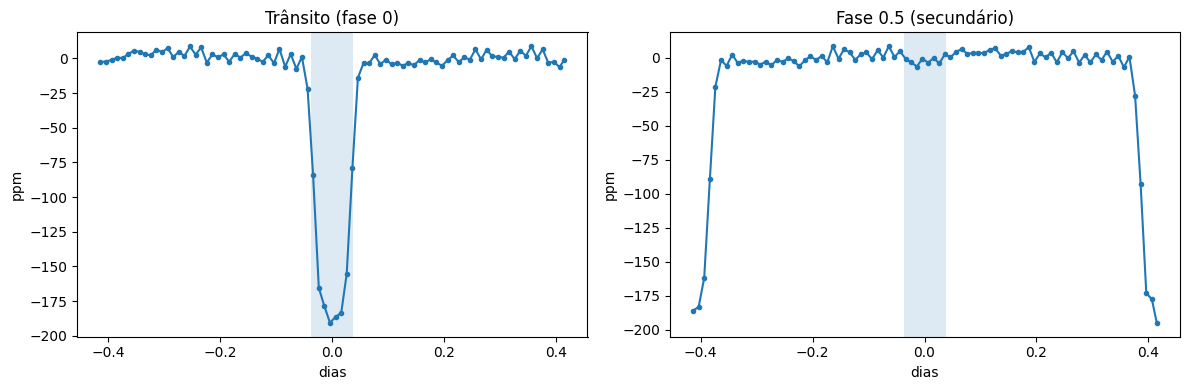

In [40]:
import glob
import numpy as np
import lightkurve as lk
import matplotlib.pyplot as plt

s = "011904151"
arqs = sorted(glob.glob(f"/kaggle/working/Kepler/{s[:4]}/{s}/*_llc.fits"))
print("Arquivos:", len(arqs))

# Efemérides do catálogo (ambos os KOIs da estrela)
P, T0, DUR = 0.837491, 131.5742, 1.8029 / 24          # K00072.01 (alvo)
P2, T02, DUR2 = 45.294060, 138.6780, 6.8586 / 24       # K00072.02 (será mascarado)

lc = lk.LightCurveCollection([lk.read(a).remove_nans().normalize() for a in arqs]).stitch()
lc = lc.remove_outliers(sigma_upper=4, sigma_lower=20)
print("Pontos:", len(lc), "| tempo:", round(float(lc.time.value.min())), "a", round(float(lc.time.value.max())), "dias")

# Remove a tendência sem "comer" os trânsitos de nenhum dos dois KOIs
m1 = lc.create_transit_mask(period=P,  transit_time=T0,  duration=DUR  * 1.5)
m2 = lc.create_transit_mask(period=P2, transit_time=T02, duration=DUR2 * 1.5)
flat = lc.flatten(window_length=101, mask=(m1 | m2))

t = np.asarray(flat.time.value, float)
f = np.asarray(flat.flux.value, float)
ok = ~m2[: len(t)] if len(m2) == len(t) else np.ones(len(t), bool)   # descarta trânsitos do KOI .02
t, f = t[ok], f[ok]

fase = ((t - T0 + 0.5 * P) % P) - 0.5 * P
fase2 = ((t - T0) % P) - 0.5 * P                       # centrada no eclipse secundário
ciclo = np.round((t - T0) / P).astype(int)
dentro = np.abs(fase) < DUR / 2
sec = np.abs(fase2) < DUR / 2
fora = ~dentro & ~sec
base, ruido = np.mean(f[fora]), np.std(f[fora])

# Ruído empírico: janelas de mesma largura em fases aleatórias, longe de 0 e de 0.5
rng = np.random.default_rng(0)
vals = []
for off in rng.uniform(0, P, 4000):
    d0 = min(off, P - off); d5 = abs(off - P / 2)
    if d0 > 1.5 * DUR and d5 > 1.5 * DUR:
        w = np.abs(((t - T0 - off + 0.5 * P) % P) - 0.5 * P) < DUR / 2
        if w.sum() > 50:
            vals.append((base - np.mean(f[w])) * 1e6)
sig = np.std(vals)

def prof(mask):
    return (base - np.mean(f[mask])) * 1e6, int(mask.sum())

par = (ciclo % 2 == 0)
d_all, n_all = prof(dentro); d_par, _ = prof(dentro & par); d_imp, _ = prof(dentro & ~par); d_sec, n_sec = prof(sec)

print(f"\nRuído por ponto fora do trânsito: {ruido*1e6:.0f} ppm | dispersão empírica da profundidade: {sig:.1f} ppm ({len(vals)} janelas)")
print(f"Trânsitos cobertos: {len(np.unique(ciclo[dentro]))} | pontos dentro: {n_all}")
print(f"\nProfundidade: {d_all:.0f} ppm  (catálogo: 195) = {d_all/sig:.0f} sigma empírico")
print(f"Pares: {d_par:.0f} | Ímpares: {d_imp:.0f} | diferença: {d_par-d_imp:.1f} ppm = {(d_par-d_imp)/(sig*np.sqrt(2)*np.sqrt(2)):.1f} sigma (aprox.)")
print(f"Secundário: {d_sec:.1f} ppm = {d_sec/sig:.1f} sigma empírico (n={n_sec})")

def binar(x, y, w):
    b = np.arange(x.min(), x.max() + w, w); i = np.digitize(x, b)
    xc = np.array([x[i == k].mean() for k in np.unique(i)]); yc = np.array([y[i == k].mean() for k in np.unique(i)])
    return xc, yc

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, x, tit in [(ax[0], fase, "Trânsito (fase 0)"), (ax[1], fase2, "Fase 0.5 (secundário)")]:
    xc, yc = binar(x, (f - base) * 1e6, 0.01)
    a.plot(xc, yc, ".-"); a.axvspan(-DUR/2, DUR/2, alpha=0.15); a.set_title(tit)
    a.set_xlabel("dias"); a.set_ylabel("ppm")
plt.tight_layout(); plt.show()

In [41]:
import os, time
import numpy as np, pandas as pd, requests
from concurrent.futures import ThreadPoolExecutor

BASE   = "/kaggle/input/datasets/vijayveersingh/kepler-and-tess-exoplanet-data/"
AMOSTRA = "/kaggle/working/amostra_koi.csv"
LOG     = "/kaggle/working/download_log.csv"
PASTA   = "/kaggle/working/Kepler"
LIMITE_MIN, N_THREADS = 10, 3

CARIMBOS = {0:"2009131105131", 1:"2009166043257", 2:"2009259160929", 3:"2009350155506",
            4:"2010078095331", 5:"2010174085026", 6:"2010265121752", 7:"2010355172524",
            8:"2011073133259", 9:"2011177032512", 10:"2011271113734", 11:"2012004120508",
            12:"2012088054726", 13:"2012179063303", 14:"2012277125453", 15:"2013011073258",
            16:"2013098041711", 17:"2013131215648"}

# 1) Amostra fixa, salva em disco
if os.path.exists(AMOSTRA):
    amostra = pd.read_csv(AMOSTRA)
else:
    koi = pd.read_csv(BASE + "q1_q8_koi_2025.02.03_04.12.15.csv", comment="#")
    rot = koi[koi["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])]
    amostra = pd.concat([rot[rot.koi_disposition == "CONFIRMED"].sample(100, random_state=1),
                         rot[rot.koi_disposition == "FALSE POSITIVE"].sample(100, random_state=1)])
    amostra = amostra[["kepoi_name", "kepid", "koi_disposition", "koi_period",
                       "koi_time0bk", "koi_duration", "koi_depth"]]
    amostra.to_csv(AMOSTRA, index=False)
kepids = sorted(amostra["kepid"].unique())
print(f"Amostra: {len(amostra)} KOIs em {len(kepids)} estrelas")

# 2) Registro do que já foi feito
feito = {}
if os.path.exists(LOG):
    for k, q, s in pd.read_csv(LOG).itertuples(index=False):
        feito[(int(k), int(q))] = s
def salva_log():
    pd.DataFrame([(k, q, s) for (k, q), s in feito.items()],
                 columns=["kepid", "q", "status"]).to_csv(LOG, index=False)

# 3) Download de um arquivo
def tarefa(kepid, q):
    s, c = f"{kepid:09d}", CARIMBOS[q]
    dest = f"{PASTA}/{s[:4]}/{s}/kplr{s}-{c}_llc.fits"
    if os.path.exists(dest) and os.path.getsize(dest) > 10000:
        return kepid, q, "OK"
    url = ("https://mast.stsci.edu/api/v0.1/Download/file?uri="
           f"mast:Kepler/url/missions/kepler/lightcurves/{s[:4]}/{s}//kplr{s}-{c}_llc.fits")
    status = "erro"
    for tent in range(3):
        try:
            r = requests.get(url, timeout=(30, 120))
            if r.status_code == 404:
                return kepid, q, "404"
            if r.status_code == 200 and r.content.startswith(b"SIMPLE"):
                os.makedirs(os.path.dirname(dest), exist_ok=True)
                open(dest + ".part", "wb").write(r.content)
                os.replace(dest + ".part", dest)
                return kepid, q, "OK"
            status = f"HTTP {r.status_code}"
        except Exception as e:
            status = f"erro {type(e).__name__}"
        time.sleep(2 * (tent + 1))
    return kepid, q, status          # não é final: será tentado de novo

# 4) Loop com limite de tempo
pend = [(k, q) for k in kepids for q in CARIMBOS if feito.get((k, q)) not in ("OK", "404")]
print(f"Pendentes: {len(pend)} de {len(kepids) * len(CARIMBOS)}")
t_ini, n_ok = time.time(), 0
with ThreadPoolExecutor(N_THREADS) as ex:
    for i in range(0, len(pend), 30):
        if time.time() - t_ini > LIMITE_MIN * 60:
            print(f"Limite de {LIMITE_MIN} min atingido, parando.")
            break
        for k, q, st in ex.map(lambda a: tarefa(*a), pend[i:i + 30]):
            feito[(k, q)] = st
            n_ok += st in ("OK", "404")
        salva_log()
        dt = time.time() - t_ini
        print(f"  {n_ok} pedidos concluídos em {dt:.0f}s ({n_ok / dt:.2f}/s)")

# 5) Resumo
log = pd.DataFrame([(k, q, s) for (k, q), s in feito.items()], columns=["kepid", "q", "status"])
print("\nStatus acumulado:", log["status"].value_counts().to_dict())
restam = len([1 for k in kepids for q in CARIMBOS if feito.get((k, q)) not in ("OK", "404")])
print("Ainda pendentes:", restam)

Amostra: 200 KOIs em 196 estrelas
Pendentes: 3528 de 3528
  30 pedidos concluídos em 9s (3.42/s)
  60 pedidos concluídos em 18s (3.30/s)
  90 pedidos concluídos em 27s (3.28/s)
  120 pedidos concluídos em 36s (3.31/s)
  150 pedidos concluídos em 45s (3.35/s)
  180 pedidos concluídos em 54s (3.35/s)
  210 pedidos concluídos em 63s (3.35/s)
  240 pedidos concluídos em 71s (3.39/s)
  270 pedidos concluídos em 80s (3.38/s)


KeyboardInterrupt: 

In [42]:
import os, glob, time, warnings
import numpy as np, pandas as pd
from astropy.io import fits
import lightkurve as lk
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")

BASE  = "/kaggle/input/datasets/vijayveersingh/kepler-and-tess-exoplanet-data/"
PASTA = "/kaggle/working/Kepler"
SAIDA = "/kaggle/working/features_lc.csv"
LIMITE_MIN = 12

amostra = pd.read_csv("/kaggle/working/amostra_koi.csv")
koi = pd.read_csv(BASE + "q1_q8_koi_2025.02.03_04.12.15.csv", comment="#")

def carrega(kid):
    s = f"{kid:09d}"; ts, fs = [], []
    for a in sorted(glob.glob(f"{PASTA}/{s[:4]}/{s}/*_llc.fits")):
        with fits.open(a) as h:
            d = h[1].data
            t, f, q = d["TIME"], d["PDCSAP_FLUX"], d["SAP_QUALITY"]
        ok = np.isfinite(t) & np.isfinite(f) & (q == 0)
        if ok.sum() < 100: continue
        t, f = t[ok].astype(float), f[ok].astype(float)
        ts.append(t); fs.append(f / np.median(f))
    if not ts: return None, None
    t, f = np.concatenate(ts), np.concatenate(fs); o = np.argsort(t)
    return t[o], f[o]

def mascara(t, P, T0, larg):
    return np.abs(((t - T0 + 0.5 * P) % P) - 0.5 * P) < larg / 2

def prepara_fase(t, f, T0, P):
    ph = (t - T0) % P; o = np.argsort(ph); ph, ff = ph[o], f[o]
    ph3 = np.concatenate([ph - P, ph, ph + P]); f3 = np.concatenate([ff, ff, ff])
    return ph3, np.concatenate([[0.0], np.cumsum(f3)])

def media_janela(ph3, cs, centros, larg):
    lo = np.searchsorted(ph3, centros - larg / 2); hi = np.searchsorted(ph3, centros + larg / 2)
    n = hi - lo
    return np.where(n > 0, (cs[hi] - cs[lo]) / np.maximum(n, 1), np.nan), n

def processa_estrela(kid, alvos):
    t, f = carrega(kid)
    if t is None:
        return [dict(kepoi_name=r.kepoi_name, kepid=kid, status="sem_arquivos") for r in alvos.itertuples()]
    todos = koi[koi.kepid == kid].dropna(subset=["koi_period", "koi_time0bk", "koi_duration"])
    efem = [(r.kepoi_name, r.koi_period, r.koi_time0bk, r.koi_duration / 24) for r in todos.itertuples()]
    m_all = np.zeros(len(t), bool)
    for _, P, T0, D in efem: m_all |= mascara(t, P, T0, 1.5 * D)
    wl = int(max(101, round(3 * max(e[3] for e in efem) * 48.98)))
    wl = min(wl + (wl % 2 == 0), 2001)
    flat = lk.LightCurve(time=t, flux=f).flatten(window_length=wl, mask=m_all)
    ff, tt = np.asarray(flat.flux.value, float), np.asarray(flat.time.value, float)
    med = np.median(ff); sd = 1.4826 * np.median(np.abs(ff - med))
    k = ff < med + 5 * sd                                  # só corta para cima
    tt, ff = tt[k], ff[k]

    saida = []
    for r in alvos.itertuples():
        d = dict(kepoi_name=r.kepoi_name, kepid=kid, n_pontos=len(tt))
        P, T0, D = r.koi_period, r.koi_time0bk, r.koi_duration / 24
        if not (np.isfinite([P, T0, D]).all() and 0 < D < 0.4 * P):
            d["status"] = "efemeride_invalida"; saida.append(d); continue
        outros = np.zeros(len(tt), bool)
        for nome, P2, T2, D2 in efem:
            if nome != r.kepoi_name: outros |= mascara(tt, P2, T2, 1.5 * D2)
        t2, f2 = tt[~outros], ff[~outros]
        fc = ((t2 - T0 + 0.5 * P) % P) - 0.5 * P
        dentro = np.abs(fc) < D / 2; n_in = int(dentro.sum())
        if n_in < 10:
            d["status"] = "poucos_pontos_em_transito"; saida.append(d); continue
        base = f2[np.abs(fc) >= D].mean()
        ph3, cs = prepara_fase(t2, f2, T0, P)
        m0, _ = media_janela(ph3, cs, np.array([0.0]), D)
        depth = base - m0[0]
        c = np.arange(0, P, D / 4)
        c = c[(np.minimum(c, P - c) > D) & (np.abs(c - P / 2) > D)]
        mj, nj = media_janela(ph3, cs, c, D); bom = nj >= 0.5 * n_in
        sig = (base - mj[bom]).std() if bom.sum() >= 10 else np.nan
        mc, _ = media_janela(ph3, cs, np.array([0.0]), D / 3)
        ms, _ = media_janela(ph3, cs, np.array([P / 2]), D)
        ciclo = np.round((t2 - T0) / P).astype(int); par = ciclo % 2 == 0
        n_par, n_imp = int((dentro & par).sum()), int((dentro & ~par).sum())
        oe = np.nan
        if n_par >= 3 and n_imp >= 3 and np.isfinite(sig):
            dp, di = base - f2[dentro & par].mean(), base - f2[dentro & ~par].mean()
            oe = (dp - di) / (sig * np.sqrt(n_in) * np.sqrt(1 / n_par + 1 / n_imp))
        d.update(status="OK", n_transitos=len(np.unique(ciclo[dentro])), n_in=n_in,
                 depth_ppm=depth * 1e6, sig_ppm=sig * 1e6,
                 snr_emp=depth / sig if np.isfinite(sig) else np.nan,
                 odd_even_sigma=oe, sec_depth_ppm=(base - ms[0]) * 1e6,
                 sec_sigma=(base - ms[0]) / sig if np.isfinite(sig) else np.nan,
                 core_ratio=(base - mc[0]) / depth if depth > 0 else np.nan,
                 depth_vs_cat=depth * 1e6 / r.koi_depth if r.koi_depth > 0 else np.nan)
        saida.append(d)
    return saida

# --- Teste de sanidade com o Kepler-10 (compare com o que medimos à mão) ---
teste = processa_estrela(11904151, koi[koi.kepoi_name == "K00072.01"])[0]
print("TESTE Kepler-10 b:", {k: (round(v, 2) if isinstance(v, float) else v) for k, v in teste.items()})
print("   (à mão: profundidade ~159 ppm | dispersão 2.4 ppm | ímpar-par -0.7 | secundário 1.1 sigma)\n")

# --- Processa a amostra (retomável) ---
feitos = set(pd.read_csv(SAIDA).kepoi_name) if os.path.exists(SAIDA) else set()
t_ini = time.time()
for kid, g in amostra.groupby("kepid"):
    g = g[~g.kepoi_name.isin(feitos)]
    if g.empty: continue
    if time.time() - t_ini > LIMITE_MIN * 60:
        print("Limite de tempo atingido: rode a célula de novo para continuar."); break
    try:
        linhas = processa_estrela(int(kid), g)
    except Exception as e:
        linhas = [dict(kepoi_name=r.kepoi_name, kepid=kid, status=f"erro: {type(e).__name__}: {str(e)[:80]}")
                  for r in g.itertuples()]
    pd.DataFrame(linhas).to_csv(SAIDA, mode="a", header=not os.path.exists(SAIDA), index=False)

# --- Resumo ---
res = pd.read_csv(SAIDA).merge(amostra[["kepoi_name", "koi_disposition"]], on="kepoi_name")
res = res.merge(koi[["kepoi_name", "koi_model_snr", "koi_impact"]], on="kepoi_name", how="left")
print(f"Processados: {len(res)} de {len(amostra)} | tempo: {time.time()-t_ini:.0f}s")
print(res["status"].value_counts().to_dict())
ok = res[res.status == "OK"].copy(); ok["y"] = (ok.koi_disposition == "CONFIRMED").astype(int)
ok["abs_odd_even"] = ok["odd_even_sigma"].abs()
print(f"\nLinhas OK: {len(ok)} | planetas: {ok.y.sum()} | falsos positivos: {(1 - ok.y).sum()}")
print("\nfeature          n   mediana(FP)  mediana(planeta)  AUC(planeta=positivo)")
for c in ["snr_emp", "abs_odd_even", "sec_sigma", "core_ratio", "depth_vs_cat", "n_transitos", "koi_model_snr", "koi_impact"]:
    x = ok.dropna(subset=[c])
    if x.y.sum() >= 10 and (1 - x.y).sum() >= 10:
        print(f"{c:15s} {len(x):4d}  {x[x.y == 0][c].median():11.2f}  {x[x.y == 1][c].median():15.2f}  {roc_auc_score(x.y, x[c]):12.3f}")

TESTE Kepler-10 b: {'kepoi_name': 'K00072.01', 'kepid': 11904151, 'n_pontos': 44586, 'status': 'OK', 'n_transitos': 1213, 'n_in': 3946, 'depth_ppm': np.float64(160.89), 'sig_ppm': np.float64(2.67), 'snr_emp': np.float64(60.34), 'odd_even_sigma': np.float64(-0.69), 'sec_depth_ppm': np.float64(3.96), 'sec_sigma': np.float64(1.49), 'core_ratio': np.float64(1.17), 'depth_vs_cat': np.float64(0.83)}
   (à mão: profundidade ~159 ppm | dispersão 2.4 ppm | ímpar-par -0.7 | secundário 1.1 sigma)

Processados: 200 de 200 | tempo: 14s
{'OK': 18}

Linhas OK: 18 | planetas: 5 | falsos positivos: 13

feature          n   mediana(FP)  mediana(planeta)  AUC(planeta=positivo)


In [43]:
import numpy as np, pandas as pd, warnings
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")

BASE = "/kaggle/input/datasets/vijayveersingh/kepler-and-tess-exoplanet-data/"
koi = pd.read_csv(BASE + "q1_q8_koi_2025.02.03_04.12.15.csv", comment="#")
lcf = pd.read_csv("/kaggle/working/features_lc.csv")

cols_koi = ["kepoi_name", "koi_disposition", "koi_period", "koi_duration", "koi_depth",
            "koi_impact", "koi_model_snr", "koi_prad", "koi_teq", "koi_steff",
            "koi_slogg", "koi_srad", "koi_kepmag"]
df = lcf[lcf.status == "OK"].merge(koi[cols_koi], on="kepoi_name", how="left")
df["y"] = (df.koi_disposition == "CONFIRMED").astype(int)

# Features derivadas da tabela (as mesmas de antes)
df["log_period"] = np.log10(df.koi_period)
df["log_depth"]  = np.log10(df.koi_depth.clip(lower=1))
df["log_snr"]    = np.log10(df.koi_model_snr.clip(lower=0.1))
df["rp_rs"]      = df.koi_prad / (109.1 * df.koi_srad)
rho = (10 ** (df.koi_slogg - 4.438)) / df.koi_srad
df["dur_ratio"]  = df.koi_duration / (13.0 * (df.koi_period / 365.25) ** (1/3) * rho ** (-1/3))
df["abs_odd_even"] = df.odd_even_sigma.abs()
df = df.replace([np.inf, -np.inf], np.nan)

feats_tab = ["koi_period", "koi_duration", "koi_depth", "koi_impact", "koi_model_snr",
             "koi_prad", "koi_teq", "koi_steff", "koi_slogg", "koi_srad", "koi_kepmag",
             "log_period", "log_depth", "log_snr", "rp_rs", "dur_ratio"]
feats_lc = ["snr_emp", "abs_odd_even", "sec_sigma", "core_ratio", "depth_vs_cat"]
print(f"Linhas: {len(df)} | planetas: {df.y.sum()} | falsos positivos: {(1 - df.y).sum()}\n")

# A) Correlação das features da curva com medidas da tabela
refs = ["koi_period", "koi_duration", "koi_depth", "koi_impact", "koi_model_snr"]
A = pd.DataFrame({r: [spearmanr(df[c], df[r], nan_policy="omit")[0] for c in feats_lc]
                  for r in refs}, index=feats_lc).round(2)
print("A) Spearman: features da curva (linhas) x medidas da tabela (colunas)")
print(A, "\n")

# B) AUC dentro de tercis de período e de duração
def por_faixa(var):
    q = pd.qcut(df[var], 3, labels=["baixo", "medio", "alto"])
    print(f"B) AUC dentro de tercis de {var}")
    print("   composição (planetas/total) por tercil:",
          {f: f"{int(df[q == f].y.sum())}/{int((q == f).sum())}" for f in ["baixo", "medio", "alto"]})
    for c in feats_lc:
        partes = []
        for f in ["baixo", "medio", "alto"]:
            g = df[q == f].dropna(subset=[c])
            ok = g.y.sum() >= 8 and (1 - g.y).sum() >= 8
            partes.append(f"{roc_auc_score(g.y, g[c]):.2f}" if ok else " n/a")
        print(f"   {c:14s} baixo={partes[0]}  medio={partes[1]}  alto={partes[2]}")
    print()
por_faixa("koi_period")
por_faixa("koi_duration")

# C) Modelo: tabela vs tabela + curva vs só curva
def avalia(cols, n_rep=10):
    aucs = []
    for s in range(n_rep):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=s)
        m = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150,
                                           min_samples_leaf=8, random_state=0)
        p = cross_val_predict(m, df[cols], df.y, groups=df.kepid, cv=cv,
                              method="predict_proba")[:, 1]
        aucs.append(roc_auc_score(df.y, p))
    return np.array(aucs)

a_tab = avalia(feats_tab)
a_both = avalia(feats_tab + feats_lc)
a_lc = avalia(feats_lc)
print("C) ROC-AUC (10 divisões diferentes, separadas por estrela)")
for nome, a in [("só tabela", a_tab), ("tabela + curva", a_both), ("só curva", a_lc)]:
    print(f"   {nome:16s} média={a.mean():.3f}  desvio entre divisões={a.std():.3f}")
d = a_both - a_tab
print(f"   Diferença pareada (tabela+curva) - (só tabela): {d.mean():+.3f}  "
      f"| positiva em {(d > 0).mean() * 100:.0f}% das divisões")

Linhas: 18 | planetas: 5 | falsos positivos: 13

A) Spearman: features da curva (linhas) x medidas da tabela (colunas)
              koi_period  koi_duration  koi_depth  koi_impact  koi_model_snr
snr_emp             0.28          0.01       0.86       -0.11           0.95
abs_odd_even       -0.07          0.34       0.01       -0.04           0.22
sec_sigma          -0.15         -0.19       0.21       -0.05           0.45
core_ratio         -0.12         -0.38       0.37        0.17           0.58
depth_vs_cat        0.23         -0.15       0.14       -0.08          -0.14 

B) AUC dentro de tercis de koi_period
   composição (planetas/total) por tercil: {'baixo': '0/6', 'medio': '2/6', 'alto': '3/6'}
   snr_emp        baixo= n/a  medio= n/a  alto= n/a
   abs_odd_even   baixo= n/a  medio= n/a  alto= n/a
   sec_sigma      baixo= n/a  medio= n/a  alto= n/a
   core_ratio     baixo= n/a  medio= n/a  alto= n/a
   depth_vs_cat   baixo= n/a  medio= n/a  alto= n/a

B) AUC dentro de tercis de 

In [44]:
def oof(cols, n_rep=10):
    P = np.zeros(len(df))
    for s in range(n_rep):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=s)
        m = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150,
                                           min_samples_leaf=8, random_state=0)
        P += cross_val_predict(m, df[cols], df.y, groups=df.kepid, cv=cv,
                               method="predict_proba")[:, 1]
    return P / n_rep

# 1) Bootstrap por estrela da diferença pareada
p_tab, p_both = oof(feats_tab), oof(feats_tab + feats_lc)
estrelas = df.kepid.unique()
idx_por = {k: np.where(df.kepid.values == k)[0] for k in estrelas}
rng = np.random.default_rng(0)
difs = []
for _ in range(1000):
    sel = rng.choice(estrelas, len(estrelas), replace=True)
    idx = np.concatenate([idx_por[k] for k in sel])
    y = df.y.values[idx]
    if y.min() == y.max(): continue
    difs.append(roc_auc_score(y, p_both[idx]) - roc_auc_score(y, p_tab[idx]))
difs = np.array(difs)
print("1) Bootstrap por estrela (1000 reamostragens)")
print(f"   AUC tabela={roc_auc_score(df.y, p_tab):.3f} | tabela+curva={roc_auc_score(df.y, p_both):.3f}")
print(f"   Diferença: média={difs.mean():+.3f} | IC 95% = [{np.percentile(difs, 2.5):+.3f}, {np.percentile(difs, 97.5):+.3f}]"
      f" | fração > 0: {(difs > 0).mean():.3f}\n")

# 2) Ablação
print("2) Ablação (AUC médio de 10 divisões)")
base_auc = roc_auc_score(df.y, p_tab)
print(f"   {'só tabela':36s} {base_auc:.3f}")
for c in feats_lc:
    a = roc_auc_score(df.y, oof(feats_tab + [c]))
    print(f"   {'tabela + ' + c:36s} {a:.3f}  ({a - base_auc:+.3f})")
tudo = roc_auc_score(df.y, p_both)
print(f"   {'tabela + todas as 5':36s} {tudo:.3f}  ({tudo - base_auc:+.3f})")
for c in feats_lc:
    a = roc_auc_score(df.y, oof(feats_tab + [x for x in feats_lc if x != c]))
    print(f"   {'tabela + todas SEM ' + c:36s} {a:.3f}  ({a - tudo:+.3f} vs. todas)")

1) Bootstrap por estrela (1000 reamostragens)
   AUC tabela=0.000 | tabela+curva=0.000
   Diferença: média=+0.000 | IC 95% = [+0.000, +0.000] | fração > 0: 0.000

2) Ablação (AUC médio de 10 divisões)
   só tabela                            0.000
   tabela + snr_emp                     0.000  (+0.000)
   tabela + abs_odd_even                0.000  (+0.000)
   tabela + sec_sigma                   0.000  (+0.000)
   tabela + core_ratio                  0.000  (+0.000)
   tabela + depth_vs_cat                0.000  (+0.000)
   tabela + todas as 5                  0.000  (+0.000)
   tabela + todas SEM snr_emp           0.000  (+0.000 vs. todas)
   tabela + todas SEM abs_odd_even      0.000  (+0.000 vs. todas)
   tabela + todas SEM sec_sigma         0.000  (+0.000 vs. todas)
   tabela + todas SEM core_ratio        0.000  (+0.000 vs. todas)
   tabela + todas SEM depth_vs_cat      0.000  (+0.000 vs. todas)


In [45]:
import shutil, os
print(os.path.exists("/kaggle/working/features_lc.csv"))   # tem que imprimir True
shutil.rmtree("/kaggle/working/Kepler", ignore_errors=True)

True


In [47]:
import glob, warnings
import numpy as np, pandas as pd
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")

f_koi = glob.glob("/kaggle/input/**/q1_q8_koi*.csv", recursive=True)[0]
f_lc = (glob.glob("/kaggle/input/datasets/carlospetito/features-lc-1000-csv/features_lc_1000.csv") +
        glob.glob("/kaggle/input/**/features_lc_1000.csv", recursive=True))[0]
koi = pd.read_csv(f_koi, comment="#")
lcf = pd.read_csv(f_lc)

cols_koi = ["kepoi_name", "koi_disposition", "koi_period", "koi_duration", "koi_depth",
            "koi_impact", "koi_model_snr", "koi_prad", "koi_teq", "koi_steff",
            "koi_slogg", "koi_srad", "koi_kepmag"]
df = lcf[lcf.status == "OK"].merge(koi[cols_koi], on="kepoi_name", how="left")
df["y"] = (df.koi_disposition == "CONFIRMED").astype(int)
df["log_period"] = np.log10(df.koi_period)
df["log_depth"]  = np.log10(df.koi_depth.clip(lower=1))
df["log_snr"]    = np.log10(df.koi_model_snr.clip(lower=0.1))
df["rp_rs"]      = df.koi_prad / (109.1 * df.koi_srad)
rho = (10 ** (df.koi_slogg - 4.438)) / df.koi_srad
df["dur_ratio"]  = df.koi_duration / (13.0 * (df.koi_period / 365.25) ** (1/3) * rho ** (-1/3))
df["abs_odd_even"] = df.odd_even_sigma.abs()
df = df.replace([np.inf, -np.inf], np.nan).reset_index(drop=True)

feats_tab = ["koi_period", "koi_duration", "koi_depth", "koi_impact", "koi_model_snr",
             "koi_prad", "koi_teq", "koi_steff", "koi_slogg", "koi_srad", "koi_kepmag",
             "log_period", "log_depth", "log_snr", "rp_rs", "dur_ratio"]
feats_lc = ["snr_emp", "abs_odd_even", "sec_sigma", "core_ratio", "depth_vs_cat"]

print(f"Linhas: {len(df)} | planetas: {df.y.sum()} | falsos positivos: {(1 - df.y).sum()} | estrelas: {df.kepid.nunique()}")
print("Fração de NaN nas features da curva (%):", (df[feats_lc].isna().mean() * 100).round(1).to_dict(), "\n")

# 1) AUC univariado (planeta = positivo) e medianas
print("1) AUC univariado")
print(f"{'feature':14s} {'n':>5s} {'med(FP)':>10s} {'med(planeta)':>13s} {'AUC':>6s}")
for c in feats_lc + ["koi_model_snr", "koi_impact", "koi_period", "koi_duration", "koi_depth", "rp_rs", "dur_ratio"]:
    x = df.dropna(subset=[c])
    print(f"{c:14s} {len(x):5d} {x[x.y == 0][c].median():10.2f} {x[x.y == 1][c].median():13.2f} {roc_auc_score(x.y, x[c]):6.3f}")

# 2) Correlação com a tabela
refs = ["koi_period", "koi_duration", "koi_depth", "koi_impact", "koi_model_snr"]
A = pd.DataFrame({r: [spearmanr(df[c], df[r], nan_policy="omit")[0] for c in feats_lc]
                  for r in refs}, index=feats_lc).round(2)
print("\n2) Spearman: features da curva x tabela"); print(A)

# 3) AUC dentro de tercis de período e de duração
def por_faixa(var):
    q = pd.qcut(df[var], 3, labels=["baixo", "medio", "alto"])
    comp = {f: f"{int(df[q == f].y.sum())}/{int((q == f).sum())}" for f in ["baixo", "medio", "alto"]}
    print(f"\n3) AUC dentro de tercis de {var} (planetas/total: {comp})")
    for c in feats_lc:
        partes = []
        for f in ["baixo", "medio", "alto"]:
            g = df[q == f].dropna(subset=[c])
            ok = g.y.sum() >= 15 and (1 - g.y).sum() >= 15
            partes.append(f"{roc_auc_score(g.y, g[c]):.2f}" if ok else " n/a")
        print(f"   {c:14s} baixo={partes[0]}  medio={partes[1]}  alto={partes[2]}")
por_faixa("koi_period"); por_faixa("koi_duration")

# 4) Modelos (mesmos hiperparâmetros de antes, sem ajuste)
def oof(cols, n_rep=10):
    P, aucs = np.zeros(len(df)), []
    for s in range(n_rep):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=s)
        m = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150,
                                           min_samples_leaf=8, random_state=0)
        p = cross_val_predict(m, df[cols], df.y, groups=df.kepid, cv=cv, method="predict_proba")[:, 1]
        P += p; aucs.append(roc_auc_score(df.y, p))
    return P / n_rep, np.array(aucs)

p_tab, a_tab = oof(feats_tab)
p_both, a_both = oof(feats_tab + feats_lc)
_, a_lc = oof(feats_lc)
print("\n4) ROC-AUC (10 divisões, separadas por estrela)")
for nome, a in [("só tabela", a_tab), ("tabela + curva", a_both), ("só curva", a_lc)]:
    print(f"   {nome:16s} média={a.mean():.3f}  desvio entre divisões={a.std():.3f}")
d = a_both - a_tab
print(f"   Diferença pareada: {d.mean():+.3f} | positiva em {(d > 0).mean() * 100:.0f}% das divisões")

# 5) Bootstrap por estrela
estrelas = df.kepid.unique()
idx_por = {k: np.where(df.kepid.values == k)[0] for k in estrelas}
rng = np.random.default_rng(0); difs = []
for _ in range(1000):
    sel = rng.choice(estrelas, len(estrelas), replace=True)
    idx = np.concatenate([idx_por[k] for k in sel]); y = df.y.values[idx]
    if y.min() != y.max():
        difs.append(roc_auc_score(y, p_both[idx]) - roc_auc_score(y, p_tab[idx]))
difs = np.array(difs)
print(f"\n5) Bootstrap por estrela: AUC tabela={roc_auc_score(df.y, p_tab):.3f} | tabela+curva={roc_auc_score(df.y, p_both):.3f}")
print(f"   Diferença: {difs.mean():+.3f} | IC 95% = [{np.percentile(difs, 2.5):+.3f}, {np.percentile(difs, 97.5):+.3f}]"
      f" | fração > 0: {(difs > 0).mean():.3f}")

# 6) Ablação
base_auc = roc_auc_score(df.y, p_tab); tudo = roc_auc_score(df.y, p_both)
print("\n6) Ablação (AUC das previsões médias de 10 divisões)")
print(f"   {'só tabela':36s} {base_auc:.3f}")
for c in feats_lc:
    a = roc_auc_score(df.y, oof(feats_tab + [c])[0])
    print(f"   {'tabela + ' + c:36s} {a:.3f}  ({a - base_auc:+.3f})")
print(f"   {'tabela + todas as 5':36s} {tudo:.3f}  ({tudo - base_auc:+.3f})")
for c in feats_lc:
    a = roc_auc_score(df.y, oof(feats_tab + [x for x in feats_lc if x != c])[0])
    print(f"   {'tabela + todas SEM ' + c:36s} {a:.3f}  ({a - tudo:+.3f} vs. todas)")

Linhas: 999 | planetas: 500 | falsos positivos: 499 | estrelas: 964
Fração de NaN nas features da curva (%): {'snr_emp': 3.0, 'abs_odd_even': 3.1, 'sec_sigma': 3.0, 'core_ratio': 0.5, 'depth_vs_cat': 0.0} 

1) AUC univariado
feature            n    med(FP)  med(planeta)    AUC
snr_emp          969      24.57         24.23  0.527
abs_odd_even     968       1.02          0.89  0.455
sec_sigma        969       0.48          0.07  0.375
core_ratio       994       1.30          1.21  0.274
depth_vs_cat     999       0.71          0.80  0.685
koi_model_snr    999      45.80         37.85  0.464
koi_impact       999       0.48          0.68  0.541
koi_period       999       3.56         10.02  0.695
koi_duration     999       3.09          3.42  0.544
koi_depth        999     388.00        492.00  0.534
rp_rs            999       0.02          0.02  0.521
dur_ratio        999       1.08          0.94  0.388

2) Spearman: features da curva x tabela
              koi_period  koi_duration  koi_d

In [48]:
from sklearn.metrics import roc_curve

# 1) Ganho por tercil de período, com bootstrap por estrela
q = pd.qcut(df.koi_period, 3, labels=["baixo", "medio", "alto"])
def boot_diff(mask, n=500, seed=0):
    sub = np.where(mask)[0]; est = df.kepid.values[sub]; ue = np.unique(est)
    por = {k: sub[est == k] for k in ue}; rng = np.random.default_rng(seed); out = []
    for _ in range(n):
        sel = rng.choice(ue, len(ue), replace=True)
        idx = np.concatenate([por[k] for k in sel]); y = df.y.values[idx]
        if y.min() != y.max():
            out.append(roc_auc_score(y, p_both[idx]) - roc_auc_score(y, p_tab[idx]))
    return np.array(out)

print("1) Ganho de AUC por tercil de período (previsões médias de 10 divisões)")
for f in ["baixo", "medio", "alto"]:
    m = (q == f).values
    d_ = boot_diff(m)
    print(f"   {f:6s} n={m.sum():3d} planetas={int(df.y[m].sum()):3d} | "
          f"tabela={roc_auc_score(df.y[m], p_tab[m]):.3f} tabela+curva={roc_auc_score(df.y[m], p_both[m]):.3f} | "
          f"diferença={d_.mean():+.3f}  IC95%=[{np.percentile(d_, 2.5):+.3f}, {np.percentile(d_, 97.5):+.3f}]")

# 2) Ponto de operação: quantos falsos positivos passam ao manter X% dos planetas
n_fp = int((1 - df.y).sum())
print(f"\n2) Falsos positivos que PASSAM (de {n_fp}) mantendo uma fração dos planetas")
for alvo in [0.90, 0.95, 0.98]:
    linhas = []
    for nome, p in [("só tabela", p_tab), ("tabela + curva", p_both)]:
        fpr, tpr, _ = roc_curve(df.y, p)
        linhas.append(f"{nome}: {np.interp(alvo, tpr, fpr) * n_fp:.0f}")
    print(f"   mantendo {alvo:.0%} dos planetas -> " + " | ".join(linhas))

# 3) Quem mudou mais de posição
df["p_tab"], df["p_both"] = p_tab, p_both
df["delta"] = df.p_both - df.p_tab
cols = ["kepoi_name", "koi_disposition", "koi_period", "p_tab", "p_both", "core_ratio", "sec_sigma"]
print("\n3a) Falsos positivos que a curva REBAIXOU mais (acertos novos):")
print(df[df.y == 0].nsmallest(8, "delta")[cols].round(2).to_string(index=False))
print("\n3b) Falsos positivos que a curva ELEVOU mais (erros novos):")
print(df[df.y == 0].nlargest(8, "delta")[cols].round(2).to_string(index=False))
print("\n3c) Planetas que a curva REBAIXOU mais (erros novos):")
print(df[df.y == 1].nsmallest(8, "delta")[cols].round(2).to_string(index=False))

1) Ganho de AUC por tercil de período (previsões médias de 10 divisões)
   baixo  n=333 planetas= 80 | tabela=0.924 tabela+curva=0.971 | diferença=+0.047  IC95%=[+0.027, +0.069]
   medio  n=333 planetas=207 | tabela=0.879 tabela+curva=0.924 | diferença=+0.045  IC95%=[+0.018, +0.076]
   alto   n=333 planetas=213 | tabela=0.889 tabela+curva=0.903 | diferença=+0.014  IC95%=[-0.011, +0.038]

2) Falsos positivos que PASSAM (de 499) mantendo uma fração dos planetas
   mantendo 90% dos planetas -> só tabela: 107 | tabela + curva: 67
   mantendo 95% dos planetas -> só tabela: 159 | tabela + curva: 92
   mantendo 98% dos planetas -> só tabela: 219 | tabela + curva: 157

3a) Falsos positivos que a curva REBAIXOU mais (acertos novos):
kepoi_name koi_disposition  koi_period  p_tab  p_both  core_ratio  sec_sigma
 K02301.01  FALSE POSITIVE        3.51   0.85    0.13        1.21       5.55
 K00822.01  FALSE POSITIVE        7.92   0.79    0.11        1.37       7.75
 K02892.01  FALSE POSITIVE       10